# Evaluación Sumativa 3: Modelamiento Predictivo Integrado

**Curso:** Estadística Computacional para la Toma de Decisiones
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial
**Universidad Andrés Bello**

---

## Información del Equipo

| Campo | Información |
|-------|-------------|
| **Número de Grupo** | 8 |
| **Integrante 1** | Matias Manriquez Ortiz |
| **Integrante 2** | Daniel Pérez Ramírez |
| **Integrante 3** | Abigaíl Robles Chávez |
| **Integrante 4** | Roberto Sánchez Saldivia |
| **Dataset Seleccionado** | *Predict Students' Dropout and Academic Success* (UCI, 2021) |
| **Fecha de Entrega** | 28/10/2026 |

Repositorio: https://github.com/MatiasManriquezO/MCDI501-grupo8 · Cuaderno maestro `notebooks/05_sumativa3_modelamiento_integrado.ipynb`

## ⚠️ IMPORTANTE: Integración con S1 y S2

Este cuaderno **cierra el proyecto** y usa de forma explícita los resultados previos:

| Fase | Cuaderno | Qué se usa aquí |
|------|----------|-----------------|
| S1 · Exploración e inferencia | `02_sumativa1_...ipynb` | Patrón MCAR y porcentaje de faltantes, matriz de correlaciones, outliers de edad, pruebas sobre aprobadas, beca y matrícula, colinealidad entre semestres (r = 0,91) |
| S2 · Validación | `03_sumativa2_...ipynb` + `data/processed/resultados_validados.csv` | Correlaciones estables e inestables, permutación de las Pruebas 1 y 3, Monte Carlo (cupos), técnica *bootstrap* (10.000 remuestras, percentil y BCa) |
| F2 · Formativa 2 (96/96) | `04_formativa2_...ipynb` | Primer modelo logístico (aprobadas y nota del 2.º sem., log(edad) y beca; será M1), las mejoras propuestas para S3 y la retroalimentación del profesor |

También responde a las tres observaciones del profesor en la retroalimentación de S2: **(1)** colinealidad entre
semestres (VIF), **(2)** imputar dentro del entrenamiento y medir el error contra los originales guardados, y
**(3)** verificar si la matrícula al día se conoce antes de desertar (fuga de información). De la retroalimentación de
la Formativa 2 incorpora: comparar eliminación, mediana y regresión contra los valores originales; mantener la partición
70/30 estratificada; ajustar tres modelos (las 4 variables de la Formativa 2, *stepwise* según AIC y uno reducido);
vigilar el VIF del par de semestres; ponderar las clases y aplicar *bootstrap* a los coeficientes del mejor modelo.

**Pregunta del proyecto:** ¿qué factores permiten anticipar, al cierre del primer año, que un estudiante deserte en
lugar de graduarse, y con qué confianza?

## Configuración del Entorno

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, auc,
                             classification_report, roc_auc_score,
                             ConfusionMatrixDisplay)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

SEMILLA = 42
B = 10_000                       # remuestras bootstrap (mismo mínimo que en S2)
OBJETIVO = 'Deserta'
# Raíz del repositorio: se busca hacia arriba la carpeta que contiene data/ y docs/,
# así las rutas funcionan aunque el cuaderno se ejecute desde notebooks/ o desde la raíz
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / 'docs').is_dir())
FIG = RAIZ / 'docs' / 'figuras' / 'S3'
FIG.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, GRIS, VERDE, MORADO = '#2a78d6', '#eb6834', '#52514e', '#1f9e74', '#7b5bd6'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'font.size': 9.5, 'axes.titlesize': 10.5, 'axes.titlelocation': 'left',
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
np.random.seed(SEMILLA)

import warnings
warnings.filterwarnings('ignore')
ETIQ = {'Log edad': 'Log(edad)', 'Admission grade': 'Nota de admisión', 'Age at enrollment': 'Edad al ingresar', 'Scholarship holder': 'Beca',
        'Gender': 'Género (hombre)', 'Curricular units 2nd sem (approved)': 'Aprobadas 2.º sem'}
et = lambda v: ETIQ.get(v, v)
print("✅ Librerías cargadas")

✅ Librerías cargadas


---
# 0. Carga de Resultados de S1 y S2

Misma preparación que S1 y S2: Dropout (1) frente a Graduate (0), sin los 794 Enrolled ni los 152 registros sin
actividad académica → **n = 3.478**. Se crean además tres indicadores 0/1 a partir de variables categóricas
(vía de ingreso para mayores de 23 años, estado civil soltero y educación secundaria previa), dos variables
derivadas de las unidades curriculares que se justifican en la sección 2.1 y la nota del 2.º semestre sin ceros
(como en S1 y en la Formativa 2, la nota 0 significa "sin nota").

In [2]:
df_completo = pd.read_csv(RAIZ / 'data' / 'processed' / 'data_con_faltantes.csv')
originales = pd.read_csv(RAIZ / 'data' / 'processed' / 'valores_originales.csv')   # solo para evaluar la imputación
validados = pd.read_csv(RAIZ / 'data' / 'processed' / 'resultados_validados.csv')  # reporte de S2

# Misma preparación que S1 y S2
df = df_completo[df_completo['Target'].isin(['Dropout', 'Graduate'])].copy()
df[OBJETIVO] = (df['Target'] == 'Dropout').astype(int)
cols_actividad = [f'Curricular units {s} sem ({t})' for s in ['1st', '2nd']
                  for t in ['enrolled', 'credited', 'evaluations']]
df = df[~(df[cols_actividad] == 0).all(axis=1)].copy().set_index('id_estudiante')

# Codificación de variables categóricas usadas más adelante (indicadores 0/1)
df['Ingreso mayores de 23'] = (df['Application mode'] == 39).astype(int)   # vía especial de admisión
df['Soltero'] = (df['Marital status'] == 1).astype(int)
df['Secundaria previa'] = (df['Previous qualification'] == 1).astype(int)

# Variables derivadas para la colinealidad entre semestres (observación del profesor; r = 0,91 en S1)
df['Aprobadas en el año'] = df['Curricular units 1st sem (approved)'] + df['Curricular units 2nd sem (approved)']
df['No aprobadas 2.º sem'] = (df['Curricular units 2nd sem (enrolled)'] - df['Curricular units 2nd sem (approved)']).clip(lower=0)
# Nota del 2.º semestre: el 0 coincide con 0 aprobadas y significa "sin nota" (S1); se deja como faltante estructural
df['Nota 2.º sem'] = df['Curricular units 2nd sem (grade)'].where(df['Curricular units 2nd sem (grade)'] > 0)

FALTANTES = ['Admission grade', 'Age at enrollment']
print(f"Muestra de análisis: {len(df):,} estudiantes | desertores {df[OBJETIVO].sum():,} ({df[OBJETIVO].mean()*100:.2f} %)")

Muestra de análisis: 3,478 estudiantes | desertores 1,344 (38.64 %)


**Resultados de S1** que se usan en este cuaderno:

In [3]:
faltantes_s1 = {v: {'n': int(df[v].isna().sum()), 'pct': round(df[v].isna().mean() * 100, 2),
                    'patron': 'MCAR (12 % por diseño, semilla 42)'} for v in FALTANTES}
faltantes_s1['Admission grade']['chi2_vs_Target'] = 'p = 0.041 (error tipo I: 5.6 % de 1.000 semillas)'
faltantes_s1['Age at enrollment']['chi2_vs_Target'] = 'p = 0.237'

correlaciones_s1 = {   # con la deserción (S1, n = 3.478)
    'Curricular units 2nd sem (approved)': -0.69, 'Curricular units 1st sem (approved)': -0.58,
    'Curricular units 2nd sem (grade) sin ceros': -0.33, 'Age at enrollment': 0.29,
    'Unemployment rate': -0.01, 'Aprobadas 1.er vs 2.º sem': 0.91}

outliers_s1 = {'Age at enrollment': {'n_40_o_mas': int((df['Age at enrollment'] >= 40).sum()),
                                     'asimetria': 1.97, 'curtosis': 3.72, 'mediana': 20}}
pd.DataFrame(faltantes_s1).T

,n,pct,patron,chi2_vs_Target
Admission grade,437,12.5600,"MCAR (12 % por diseño, semilla 42)",p = 0.041 (error tipo I: 5.6 % de 1.000 semillas)
Age at enrollment,406,11.6700,"MCAR (12 % por diseño, semilla 42)",p = 0.237


**Resultados de S2** (reporte de resultados validados):

In [4]:
correlaciones_estables_s2 = ['Curricular units 2nd sem (approved)', 'Curricular units 1st sem (approved)',
                             'Age at enrollment', 'Curricular units 2nd sem (grade) sin ceros']
correlaciones_inestables_s2 = ['Unemployment rate']          # IC bootstrap [-0.04; 0.03]
parametros_validados_s2 = {
    'Proporción que deserta (%)': (38.64, 37.09, 40.31),        # BCa, Tabla 1 de S2
    'Edad media (cautela: usar mediana 20)': (23.61, 23.33, 23.90),
    'Prueba 1 aprobadas, p permutación': 0.0001,
    'Prueba 3 beca, p permutación': 0.0001,
    'Cupos de tutoría al 95 % (cohorte de 1.000)': 412,
}
validados[['Tipo', 'Resultado de S1', 'Validación en S2', 'Estado']]

,Tipo,Resultado de S1,Validación en S2,Estado
0,Parámetro,Proporción que deserta,"Clásico, percentil y BCa coinciden; Monte Carl...",Robusto
1,Parámetro,Nota de admisión media,"Clásico, percentil y BCa coinciden; faltantes ...",Robusto
2,Parámetro,"Unidades aprobadas medias, 2.º sem.","Clásico, percentil y BCa coinciden",Robusto
3,Parámetro,Edad media al ingresar,"IC estable (BCa se corre 0,009 años), pero la ...",Cautela: usar mediana
4,Prueba,"Prueba 1: aprobadas 2.º sem. (Welch, d = −1,94)","Permutación p = 0,0001; ninguna réplica tan ex...",Robusto
5,Prueba,"Prueba 3: beca y deserción (χ², V = 0,32)","Permutación p = 0,0001",Robusto
6,Prueba,"Comprobación MCAR (χ², p = 0,041)","Permutación p = 0,040: confirma un falso posit...",Cautela: error tipo I
7,Correlación,Aprobadas 2.º sem. – deserción,"IC bootstrap [-0,71; -0,66]",Robusta
8,Correlación,Aprobadas 1.er – 2.º sem.,"IC bootstrap [0,90; 0,92]",Robusta
9,Correlación,Nota 2.º sem. (sin ceros) – deserción,"IC bootstrap [-0,37; -0,30]",Robusta


---
# PARTE 1: Manejo de Datos Faltantes

## 1.1 Resumen de Análisis de S1

No se repite el análisis; se usa como insumo:

- **Variables con faltantes:** `Admission grade` (437 en la muestra, 12,56 %) y `Age at enrollment` (406, 11,67 %).
  El resto del dataset está completo.
- **Patrón:** **MCAR**, generado con semilla 42 en `00_generacion_faltantes.ipynb` y verificado en S1 con pruebas χ²
  frente al desenlace (edad p = 0,237; nota p = 0,041, que S1 y S2 explicaron como error tipo I: 5,6 % de 1.000
  semillas da p < 0,05 y la permutación de S2 dio p = 0,040).
- **Consecuencia para S3:** con MCAR, eliminar filas no sesga pero pierde potencia, y cualquier imputación razonable
  debería conservar las relaciones. Como guardamos los **valores verdaderos** (`valores_originales.csv`), podemos medir
  el error real de cada estrategia, algo que en un proyecto real no es posible.

**Decisión de diseño (observación del profesor):** la partición 70/30 se hace **antes** de imputar. Los modelos de
imputación se ajustan solo con entrenamiento y se aplican tal cual a prueba, para que el conjunto de prueba no
"filtre" información al modelo.

In [5]:
# La partición se hace ANTES de imputar: todo lo que se "aprende" de los datos (medianas, regresiones,
# escalas, umbrales) se estima solo en entrenamiento y luego se aplica a prueba.
idx_train, idx_test = train_test_split(df.index, test_size=0.3, random_state=SEMILLA, stratify=df[OBJETIVO])
train, test = df.loc[idx_train].copy(), df.loc[idx_test].copy()
print(f"Entrenamiento: {len(train):,} ({train[OBJETIVO].mean()*100:.2f} % desertores) | "
      f"Prueba: {len(test):,} ({test[OBJETIVO].mean()*100:.2f} % desertores)")
print(pd.DataFrame({'train': train[FALTANTES].isna().sum(), 'test': test[FALTANTES].isna().sum()}))

Entrenamiento: 2,434 (38.66 % desertores) | Prueba: 1,044 (38.60 % desertores)
                   train  test
Admission grade      294   143
Age at enrollment    288   118


## 1.2 Imputación por Regresión Lineal

**Selección de predictores.** Para cada variable con faltantes se eligieron 4–5 predictores de la matriz de
correlaciones (procedimiento de S1), con dos condiciones: (a) no tener faltantes, para poder predecir todas las filas,
y (b) que la correlación sea **estable** según el *bootstrap* de S2 (10.000 remuestras, IC percentil sin el 0).
No se usa la variable objetivo como predictor, para no mezclar la imputación con el desenlace que se quiere predecir.

In [6]:
# Matriz de correlaciones (procedimiento de S1) restringida a casos completos de entrenamiento
candidatos = ['Previous qualification (grade)', 'Secundaria previa', 'Curricular units 1st sem (approved)',
              'Curricular units 1st sem (grade)', 'Application order', 'Ingreso mayores de 23', 'Soltero',
              'Daytime/evening attendance', 'Displaced', 'Scholarship holder', 'Gender']
corr_imp = train[FALTANTES + candidatos].corr().loc[candidatos, FALTANTES]
display(corr_imp.round(3).sort_values('Admission grade', key=abs, ascending=False))

PRED_IMP = {
    'Admission grade': ['Previous qualification (grade)', 'Secundaria previa',
                        'Curricular units 1st sem (approved)', 'Application order'],
    'Age at enrollment': ['Ingreso mayores de 23', 'Soltero', 'Daytime/evening attendance',
                          'Secundaria previa', 'Displaced'],
}

# Estabilidad de esas correlaciones con bootstrap (técnica de S2, 10.000 remuestras, percentil)
rng = np.random.default_rng(SEMILLA)
filas = []
for v, preds in PRED_IMP.items():
    cc = train.dropna(subset=[v])
    idx = rng.integers(0, len(cc), size=(B, len(cc)))
    for p in preds:
        x, yv = cc[p].to_numpy(float), cc[v].to_numpy(float)
        xb, yb = x[idx], yv[idx]
        xb = xb - xb.mean(1, keepdims=True); yb = yb - yb.mean(1, keepdims=True)
        rb = (xb * yb).sum(1) / np.sqrt((xb**2).sum(1) * (yb**2).sum(1))
        lo, hi = np.percentile(rb, [2.5, 97.5])
        filas.append({'Variable imputada': v, 'Predictor': p, 'r': np.corrcoef(x, yv)[0, 1],
                      'IC 2.5 %': lo, 'IC 97.5 %': hi, 'Estable (IC sin 0)': (lo > 0) or (hi < 0)})
estab_imp = pd.DataFrame(filas)
estab_imp

,Admission grade,Age at enrollment
Previous qualification (grade),0.5640,-0.1050
Curricular units 1st sem (grade),0.1770,-0.2740
Curricular units 1st sem (approved),0.1580,-0.1210
Secundaria previa,-0.1460,-0.3680
Application order,-0.0730,-0.2920
Ingreso mayores de 23,-0.0670,0.6430
Soltero,-0.0170,-0.6070
Gender,-0.0030,0.2040
Daytime/evening attendance,-0.0020,-0.4420
Displaced,0.0020,-0.3670


,Variable imputada,Predictor,r,IC 2.5 %,IC 97.5 %,Estable (IC sin 0)
0,Admission grade,Previous qualification (grade),0.5638,0.5224,0.6045,True
1,Admission grade,Secundaria previa,-0.1460,-0.1959,-0.0975,True
2,Admission grade,Curricular units 1st sem (approved),0.1582,0.1137,0.2020,True
3,Admission grade,Application order,-0.0731,-0.1054,-0.0406,True
4,Age at enrollment,Ingreso mayores de 23,0.6429,0.6087,0.6750,True
5,Age at enrollment,Soltero,-0.6066,-0.6473,-0.5630,True
6,Age at enrollment,Daytime/evening attendance,-0.4421,-0.4894,-0.3947,True
7,Age at enrollment,Secundaria previa,-0.3685,-0.4128,-0.3222,True
8,Age at enrollment,Displaced,-0.3671,-0.4010,-0.3327,True


- **Nota de admisión:** su mejor predictor es la nota de la educación previa (r = 0,56, IC [0,52; 0,60]); se agregan
  secundaria previa, aprobadas del 1.er semestre y orden de postulación (correlaciones débiles, pero todas estables).
- **Edad al ingresar:** la explican la vía de ingreso para mayores de 23 (r = 0,64), ser soltero (−0,61), la jornada
  diurna (−0,44), la secundaria previa (−0,37) y vivir desplazado (−0,37).
- Los nueve IC *bootstrap* excluyen el cero, así que todas las relaciones usadas son estables.

In [7]:
def imputar_por_regresion(df_train, df_test, var_objetivo, predictores):
    # Imputa valores faltantes usando regresión lineal múltiple ajustada SOLO con casos completos de entrenamiento.
    # Devuelve copias de train y test imputadas, el modelo OLS y los índices imputados.
    completos = df_train.dropna(subset=[var_objetivo] + predictores)
    X = sm.add_constant(completos[predictores])
    modelo = sm.OLS(completos[var_objetivo], X).fit()
    salida, imputados = [], {}
    for nombre, d in [('train', df_train), ('test', df_test)]:
        d = d.copy()
        faltan = d[var_objetivo].isna()
        Xf = sm.add_constant(d.loc[faltan, predictores], has_constant='add')
        d.loc[faltan, var_objetivo] = modelo.predict(Xf)
        imputados[nombre] = d.index[faltan]
        salida.append(d)
    return salida[0], salida[1], modelo, imputados

modelos_imp, imputados = {}, {}
train_C, test_C = train.copy(), test.copy()
for v, preds in PRED_IMP.items():
    train_C, test_C, modelos_imp[v], imputados[v] = imputar_por_regresion(train_C, test_C, v, preds)
    m = modelos_imp[v]
    print(f"\n=== {v} ===  n ajuste = {int(m.nobs)} | R² = {m.rsquared:.3f} | R² ajustado = {m.rsquared_adj:.3f}")
    print(m.summary2().tables[1][['Coef.', 'Std.Err.', 'P>|t|']].round(4))
    print(f"Valores imputados: {len(imputados[v]['train'])} en entrenamiento + {len(imputados[v]['test'])} en prueba "
          f"= {len(imputados[v]['train']) + len(imputados[v]['test'])}")


=== Admission grade ===  n ajuste = 2140 | R² = 0.343 | R² ajustado = 0.342
                                      Coef.  Std.Err.  P>|t|
const                               49.5064    2.6575 0.0000
Previous qualification (grade)       0.5966    0.0193 0.0000
Secundaria previa                   -4.4491    0.6746 0.0000
Curricular units 1st sem (approved)  0.4715    0.0803 0.0000
Application order                   -0.3143    0.1969 0.1106
Valores imputados: 294 en entrenamiento + 143 en prueba = 437

=== Age at enrollment ===  n ajuste = 2146 | R² = 0.612 | R² ajustado = 0.611
                             Coef.  Std.Err.  P>|t|
const                      36.4383    0.4841 0.0000
Ingreso mayores de 23       7.7584    0.3168 0.0000
Soltero                    -8.2857    0.3812 0.0000
Daytime/evening attendance -3.8596    0.3547 0.0000
Secundaria previa          -3.4562    0.2917 0.0000
Displaced                  -1.3029    0.2327 0.0000
Valores imputados: 288 en entrenamiento + 118 en pru

**Valores imputados:** 437 notas de admisión (294 en entrenamiento y 143 en prueba) y 406 edades (288 y 118), en
total **843 valores**. Los coeficientes tienen el signo esperado: la nota previa empuja la nota de admisión
(+0,60 puntos por punto) y quienes ingresan por la vía de mayores de 23 años tienen en promedio 7,8 años más.
El orden de postulación no es significativo en el modelo de la nota (p = 0,11), pero se mantiene porque su
correlación es estable y su efecto en la predicción es marginal.

### Verificación de supuestos y desempeño

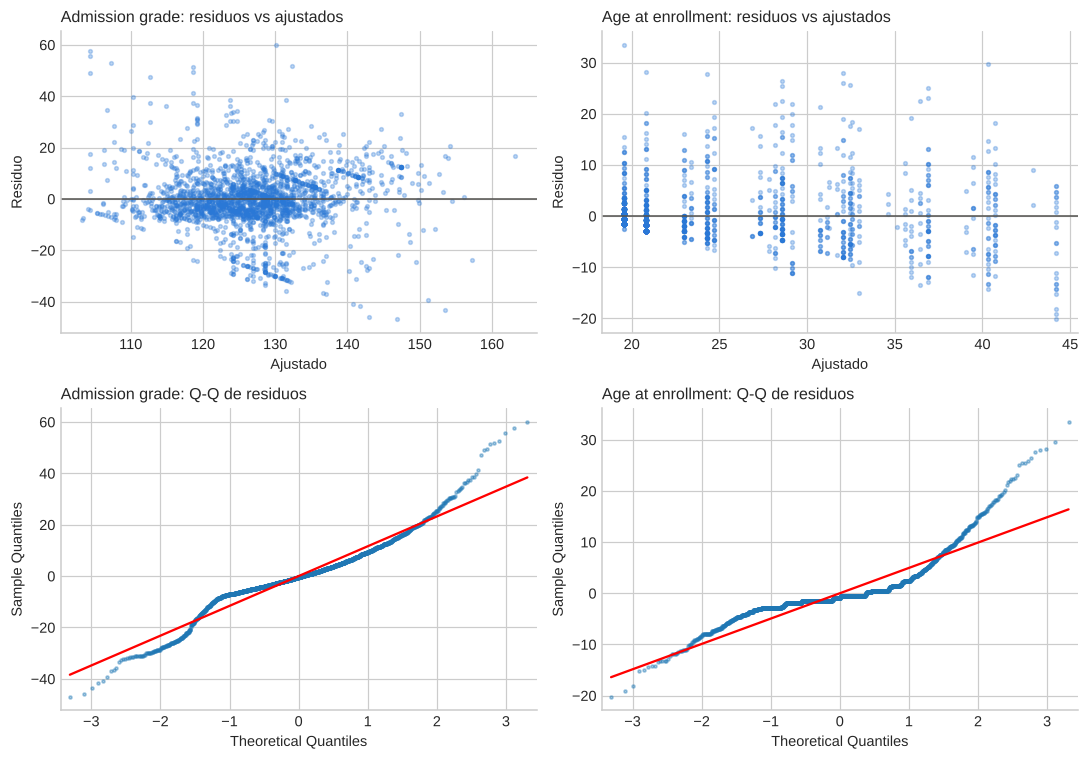

,R²,RMSE CV (5 part.),Desv. estándar de la variable,VIF máximo,Breusch-Pagan p,Asimetría residuos
Variable,,,,,,
Admission grade,0.3434,11.6162,14.3242,1.0601,0.0000,0.1452
Age at enrollment,0.6123,4.9703,7.9606,1.3541,0.0000,1.8104


In [8]:
# Supuestos de los modelos de imputación: VIF, homocedasticidad (Breusch-Pagan), normalidad de residuos y CV
diag_imp = []
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for j, (v, m) in enumerate(modelos_imp.items()):
    X = m.model.exog
    vifs = [variance_inflation_factor(X, i) for i in range(1, X.shape[1])]
    bp = het_breuschpagan(m.resid, X)
    # RMSE por validación cruzada de 5 particiones (solo casos completos de entrenamiento)
    cc = train.dropna(subset=[v]); preds = PRED_IMP[v]
    rmse_cv = []
    for a, b in KFold(5, shuffle=True, random_state=SEMILLA).split(cc):
        mm = sm.OLS(cc[v].iloc[a], sm.add_constant(cc[preds].iloc[a])).fit()
        pr = mm.predict(sm.add_constant(cc[preds].iloc[b], has_constant='add'))
        rmse_cv.append(np.sqrt(np.mean((cc[v].iloc[b] - pr) ** 2)))
    diag_imp.append({'Variable': v, 'R²': m.rsquared, 'RMSE CV (5 part.)': np.mean(rmse_cv),
                     'Desv. estándar de la variable': cc[v].std(), 'VIF máximo': max(vifs),
                     'Breusch-Pagan p': bp[1], 'Asimetría residuos': stats.skew(m.resid)})
    axs[0, j].scatter(m.fittedvalues, m.resid, s=6, alpha=0.3, color=AZUL)
    axs[0, j].axhline(0, color=GRIS, lw=1)
    axs[0, j].set(title=f'{v}: residuos vs ajustados', xlabel='Ajustado', ylabel='Residuo')
    sm.qqplot(m.resid, line='s', ax=axs[1, j], markersize=2, alpha=0.4)
    axs[1, j].set_title(f'{v}: Q-Q de residuos')
plt.tight_layout(); plt.show()
pd.DataFrame(diag_imp).set_index('Variable')

- **Multicolinealidad:** VIF máximo 1,06 y 1,35 → sin problemas.
- **Linealidad y homocedasticidad:** el gráfico de residuos muestra bandas por la naturaleza discreta de los predictores
  (indicadores 0/1). Breusch-Pagan rechaza homocedasticidad en ambos modelos (p < 0,001): el error es mayor en algunos
  grupos (por ejemplo, la edad varía mucho más entre quienes ingresan como mayores de 23).
- **Normalidad de residuos:** razonable para la nota (asimetría 0,15); la edad tiene residuos sesgados a la derecha
  (asimetría 1,81), herencia de la asimetría que ya mostró S1.
- **¿Invalida esto la imputación?** No. Para imputar se usa la **predicción puntual**, que sigue siendo insesgada con
  heterocedasticidad; lo que se ve afectado son los errores estándar del modelo de imputación, que no usamos.
- **Desempeño:** R² = 0,34 (nota) y 0,61 (edad). El RMSE por validación cruzada (11,6 puntos y 5,0 años) es menor que
  la desviación estándar de cada variable (14,3 y 8,0), es decir, el modelo predice mejor que asignar el promedio.

In [9]:
# Error de imputación contra los valores verdaderos guardados en 00 (nunca usados para ajustar)
verdad = originales.pivot(index='id_estudiante', columns='variable', values='valor_original')
mediana_train = train[FALTANTES].median()
filas = []
for v in FALTANTES:
    ids = list(imputados[v]['train']) + list(imputados[v]['test'])
    real = verdad.loc[ids, v]
    imp_reg = pd.concat([train_C, test_C]).loc[ids, v]
    for nombre, est in [('B: mediana', pd.Series(mediana_train[v], index=ids)), ('C: regresión', imp_reg)]:
        err = est.values - real.values
        filas.append({'Variable': v, 'Estrategia': nombre, 'n imputados': len(ids),
                      'RMSE': np.sqrt(np.mean(err ** 2)), 'MAE': np.mean(np.abs(err)), 'Sesgo medio': err.mean()})
error_imp = pd.DataFrame(filas).set_index(['Variable', 'Estrategia'])
error_imp

n imputados    RMSE     MAE  Sesgo medio
Variable          Estrategia                                            
Admission grade   B: mediana            437 15.4064 11.6497      -0.7568
                  C: regresión          437 12.8732  8.8591      -0.6029
Age at enrollment B: mediana            406  8.7162  5.0172      -3.4754
                  C: regresión          406  4.6041  2.9423       0.2089

**Error real frente a los valores verdaderos:** la regresión reduce el RMSE un **16 %** en la nota (12,9 frente a 15,4)
y un **47 %** en la edad (4,6 frente a 8,7 años). La mediana, además, **sesga** la edad: imputa 20 años a todos y se
equivoca en promedio −3,5 años, porque los faltantes MCAR incluyen también a estudiantes mayores; la regresión casi
no tiene sesgo (+0,2 años).

## 1.3 Comparación de Estrategias

Tres versiones del dataset, todas con la misma partición: **A** elimina las filas con algún faltante, **B** imputa la
mediana de entrenamiento y **C** imputa con las regresiones anteriores. Como referencia se usa el dataset con los
valores verdaderos, que solo sirve para comparar.

In [10]:
# A: eliminación de filas con faltantes (en train y test por separado)
train_A, test_A = train.dropna(subset=FALTANTES).copy(), test.dropna(subset=FALTANTES).copy()
# B: imputación simple con la mediana de entrenamiento
imp_med = SimpleImputer(strategy='median').fit(train[FALTANTES])
train_B, test_B = train.copy(), test.copy()
train_B[FALTANTES] = imp_med.transform(train[FALTANTES]); test_B[FALTANTES] = imp_med.transform(test[FALTANTES])
# C: imputación por regresión (ya construida: train_C, test_C)

DATASETS = {'A: Eliminar': (train_A, test_A), 'B: Imp. simple': (train_B, test_B), 'C: Imp. regresión': (train_C, test_C)}

# Referencia: datos completos verdaderos (solo para comparar, no para modelar)
df_verdad = df.copy()
for v in FALTANTES:
    df_verdad.loc[verdad.index.intersection(df.index), v] = df_verdad.loc[verdad.index.intersection(df.index), v].fillna(
        verdad.loc[verdad.index.intersection(df.index), v])
assert df_verdad[FALTANTES].isna().sum().sum() == 0

In [11]:
corr_ref = ['Deserta', 'Curricular units 2nd sem (approved)', 'Scholarship holder', 'Previous qualification (grade)',
            'Ingreso mayores de 23']
filas = []
todos = {'Verdad (sin faltantes)': df_verdad, **{k: pd.concat(v) for k, v in DATASETS.items()}}
for nombre, d in todos.items():
    fila = {'Estrategia': nombre, 'n': len(d), '% de la muestra': len(d) / len(df) * 100}
    for v in FALTANTES:
        fila[f'{v} media'] = d[v].mean(); fila[f'{v} desv.'] = d[v].std()
        if nombre != 'Verdad (sin faltantes)':
            fila[f'{v} KS vs verdad'] = stats.ks_2samp(d[v], df_verdad[v]).statistic
        fila[f'r({v}, Deserta)'] = d[v].corr(d['Deserta'])
    filas.append(fila)
comparacion_estrategias = pd.DataFrame(filas).set_index('Estrategia').T
display(comparacion_estrategias)

# Preservación de las correlaciones: diferencia absoluta media frente a la matriz verdadera
ref = df_verdad[FALTANTES + corr_ref].corr().loc[FALTANTES, corr_ref]
pres = {k: (pd.concat(v)[FALTANTES + corr_ref].corr().loc[FALTANTES, corr_ref] - ref).abs().mean().mean()
        for k, v in DATASETS.items()}
print("Diferencia absoluta media de correlaciones frente a los datos verdaderos:")
print(pd.Series(pres).round(4))

Estrategia,Verdad (sin faltantes),A: Eliminar,B: Imp. simple,C: Imp. regresión
n,3478.0000,2681.0000,3478.0000,3478.0000
% de la muestra,100.0000,77.0845,100.0000,100.0000
Admission grade media,126.9135,126.9670,126.8184,126.8377
Admission grade desv.,14.3900,14.2114,13.3179,13.6507
"r(Admission grade, Deserta)",-0.1278,-0.1329,-0.1161,-0.1292
Age at enrollment media,23.5969,23.5524,23.1912,23.6213
Age at enrollment desv.,7.9300,7.8711,7.5345,7.7813
"r(Age at enrollment, Deserta)",0.2756,0.2818,0.2695,0.2763
Admission grade KS vs verdad,NaN,0.0078,0.0630,0.0178
Age at enrollment KS vs verdad,NaN,0.0048,0.0578,0.0578


Diferencia absoluta media de correlaciones frente a los datos verdaderos:
A: Eliminar         0.0060
B: Imp. simple      0.0149
C: Imp. regresión   0.0105
dtype: float64


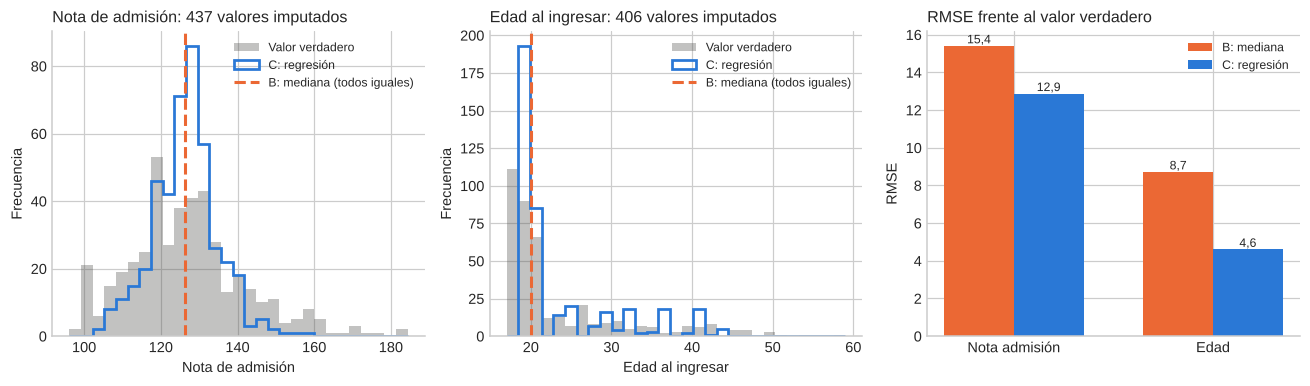

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for j, v in enumerate(FALTANTES):
    ids = list(imputados[v]['train']) + list(imputados[v]['test'])
    real = verdad.loc[ids, v]
    bins = np.linspace(real.min(), real.max(), 30)
    axs[j].hist(real, bins=bins, color=GRIS, alpha=0.35, label='Valor verdadero')
    axs[j].hist(pd.concat([train_C, test_C]).loc[ids, v], bins=bins, histtype='step', lw=1.8, color=AZUL,
                label='C: regresión')
    axs[j].axvline(mediana_train[v], color=NARANJA, lw=2, ls='--', label='B: mediana (todos iguales)')
    axs[j].set(title=f'{et(v)}: {len(ids)} valores imputados', xlabel=et(v), ylabel='Frecuencia')
    axs[j].legend(fontsize=8)
rm = error_imp['RMSE'].unstack()
x = np.arange(len(rm.index)); w = 0.35
axs[2].bar(x - w/2, rm['B: mediana'], w, color=NARANJA, label='B: mediana')
axs[2].bar(x + w/2, rm['C: regresión'], w, color=AZUL, label='C: regresión')
for xi, (b_, c_) in enumerate(zip(rm['B: mediana'], rm['C: regresión'])):
    axs[2].text(xi - w/2, b_, f'{b_:.1f}'.replace('.', ','), ha='center', va='bottom', fontsize=8)
    axs[2].text(xi + w/2, c_, f'{c_:.1f}'.replace('.', ','), ha='center', va='bottom', fontsize=8)
axs[2].set_xticks(x, ['Nota admisión', 'Edad']); axs[2].set(title='RMSE frente al valor verdadero', ylabel='RMSE')
axs[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/s3_fig1_imputacion.png'); plt.show()

| Criterio | A: Eliminar | B: Mediana | C: Regresión |
|---|---|---|---|
| Tamaño de muestra | 2.681 (77,1 %): se pierden 797 estudiantes | 3.478 | 3.478 |
| Desviación estándar (verdad: nota 14,39; edad 7,93) | 14,21; 7,87 | 13,32; 7,53 (encoge la varianza) | 13,65; 7,78 |
| r(edad, deserción) (verdad 0,276) | 0,282 | 0,270 (se atenúa) | 0,276 |
| Diferencia media de correlaciones vs verdad | 0,006 | 0,015 | 0,011 |
| RMSE de los valores imputados (nota; edad) | — | 15,4; 8,7 | 12,9; 4,6 |

**Estrategia elegida:** **C (imputación por regresión).**

**Justificación:** A conserva muy bien las distribuciones (es lo esperable con MCAR), pero pierde el 23 % de la
muestra y, con ello, potencia y casos de la clase minoritaria. Entre las estrategias que conservan el tamaño, C
recupera mejor la varianza y las correlaciones de S1 (la correlación edad–deserción queda igual a la verdadera) y
reduce a la mitad el error de la edad. Su costo es que, al imputar una predicción sin ruido, también encoge algo la
varianza (13,65 frente a 14,39 en la nota). En la Parte 3 se verifica si esta elección cambia el modelo final.

---
# PARTE 2: Regresión Logística

## 2.1 Preparación de Datos

### Variable objetivo y verificación de fuga de información

In [13]:
# ¿La matrícula al día se conoce antes de desertar? (observación del profesor en S2)
t = df.assign(Grupo=np.select([df[OBJETIVO] == 0, df['Curricular units 2nd sem (approved)'] == 0],
                              ['Graduados', 'Desertores sin aprobar en 2.º sem'], 'Desertores con aprobadas en 2.º sem'))
fuga = t.groupby('Grupo').agg(n=('Tuition fees up to date', 'size'),
                              pct_matricula_atrasada=('Tuition fees up to date', lambda s: (1 - s.mean()) * 100),
                              pct_deudor=('Debtor', lambda s: s.mean() * 100))
fuga

,n,pct_matricula_atrasada,pct_deudor
Grupo,,,
Desertores con aprobadas en 2.º sem,694,28.8184,23.4870
Desertores sin aprobar en 2.º sem,650,36.3077,20.4615
Graduados,2134,1.2184,4.5455


**¿La matrícula al día se conoce antes de desertar?** El dataset no indica en qué fecha se registra. Los datos
sugieren que **no** es una variable previa: solo el 1,2 % de los graduados aparece con matrícula atrasada (para
titularse hay que estar al día), mientras que el atraso sube de 28,8 % a 36,3 % entre los desertores que ya no aprobaron
nada en el 2.º semestre, es decir, se concentra en quienes probablemente ya se habían ido. Lo mismo ocurre con la
condición de deudor. Por eso **se excluyen ambas variables** de los candidatos y su efecto se revisa como
sensibilidad al final de la Parte 2. Esto no contradice S1 (la asociación existe, z = 26,42), sino que distingue
**asociación** de **variable útil para anticipar**.

### Outliers de S1, estandarización y codificación

In [14]:
d_train, d_test = DATASETS['C: Imp. regresión']
d_train, d_test = d_train.copy(), d_test.copy()

# Outliers de S1: edad (186 estudiantes ≥ 40). Se conservan y se acotan (winsorización) al percentil 99 de entrenamiento.
p99_edad = d_train['Age at enrollment'].quantile(0.99)
n_acot = int((d_train['Age at enrollment'] > p99_edad).sum() + (d_test['Age at enrollment'] > p99_edad).sum())
for d in (d_train, d_test):
    d['Age at enrollment'] = d['Age at enrollment'].clip(upper=p99_edad)
print(f"Edad acotada en P99 de entrenamiento = {p99_edad:.0f} años → {n_acot} valores modificados (train + test)")

def agregar_variables_f2(trn, tst):
    # Variables del modelo de la Formativa 2: nota del 2.º sem. sin ceros (mediana de entrenamiento para los
    # 650 estudiantes sin nota, igual que en F2) y logaritmo de la edad (recomendación de S2)
    med = trn['Nota 2.º sem'].median()
    for d in (trn, tst):
        d['Nota 2.º sem'] = d['Nota 2.º sem'].fillna(med)
        d['Log edad'] = np.log(d['Age at enrollment'])
    return med

med_nota = agregar_variables_f2(d_train, d_test)
print(f"Nota 2.º sem.: {int(df['Nota 2.º sem'].isna().sum())} estudiantes sin nota (todos con 0 aprobadas) imputados con la mediana de entrenamiento = {med_nota:.2f}")

# Conjunto de candidatos (sin variables con riesgo de fuga: matrícula al día y deudor)
NUMERICAS = ['Curricular units 2nd sem (approved)', 'Aprobadas en el año', 'No aprobadas 2.º sem',
             'Curricular units 2nd sem (evaluations)', 'Nota 2.º sem', 'Log edad',
             'Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
             'Unemployment rate', 'Inflation rate', 'GDP']
BINARIAS = ['Scholarship holder', 'Gender', 'Displaced', 'International', 'Ingreso mayores de 23',
            'Soltero', 'Daytime/evening attendance', 'Educational special needs']
CANDIDATAS = NUMERICAS + BINARIAS
# 'Curricular units 2nd sem (approved)' se estandariza para M1, pero no entra al conjunto de selección automática:
# allí lo reemplazan 'Aprobadas en el año' y 'No aprobadas 2.º sem' (ver la verificación de colinealidad)
# 'Log edad' tampoco entra: la edad ya está como candidata (acotada) y ambas medirían lo mismo
CANDIDATAS_SEL = [c for c in CANDIDATAS if c not in ('Curricular units 2nd sem (approved)', 'Log edad')]

scaler = StandardScaler().fit(d_train[NUMERICAS])
def preparar_X(d):
    X = d[CANDIDATAS].copy().astype(float)
    X[NUMERICAS] = scaler.transform(d[NUMERICAS])
    return X

X_train, X_test = preparar_X(d_train), preparar_X(d_test)
y_train, y_test = d_train[OBJETIVO], d_test[OBJETIVO]
print(f"X_train {X_train.shape} | X_test {X_test.shape} | candidatas para selección automática: {len(CANDIDATAS_SEL)}")

Edad acotada en P99 de entrenamiento = 50 años → 38 valores modificados (train + test)
Nota 2.º sem.: 650 estudiantes sin nota (todos con 0 aprobadas) imputados con la mediana de entrenamiento = 12.83
X_train (2434, 20) | X_test (1044, 20) | candidatas para selección automática: 18


- **Outliers de S1:** los 186 estudiantes de 40 años o más son casos reales (adultos que retoman estudios) y S1 mostró
  que desertan más, así que **no se eliminan**. Para limitar su palanca en un modelo lineal en el logit, la edad se
  acota (winsorización) en el percentil 99 de entrenamiento (50 años): solo cambian 38 valores. Su influencia se
  revisa con la distancia de Cook en 2.4.
- **Estandarización:** las numéricas se estandarizan con media y desviación de entrenamiento (los OR numéricos se
  leen "por una desviación estándar"; también se reportan por unidad original).
- **Codificación:** las variables categóricas con códigos (estado civil, modo de postulación, calificación previa) se
  convierten en indicadores 0/1 interpretables; las binarias se dejan como 0/1.
- **Variables de la Formativa 2:** la nota del 2.º semestre tiene 650 estudiantes "sin nota", que son exactamente los
  que no aprobaron ninguna unidad. Como en la Formativa 2, se imputan con la mediana de entrenamiento (12,83). El
  indicador "sin nota" que propusimos en la Formativa 2 no se puede usar: los 650 desertaron, así que separa
  perfectamente las clases y su coeficiente no converge (la información ya la llevan las aprobadas). La edad se usa
  en logaritmo solo en M1, para replicar la Formativa 2.
- **Conjunto de candidatos:** 18 variables sin riesgo de fuga, incluida la nota del 2.º semestre (estable en S2). La
  tasa de desempleo (inestable en S2) no entra a M1, pero queda como candidata para que la selección automática la
  evalúe; ningún método la eligió.

### Colinealidad entre semestres (observación del profesor)

In [15]:
# Verificación: las variables crudas de ambos semestres (lo que eligió una primera selección automática)
crudas = ['Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (enrolled)']
derivadas = ['Aprobadas en el año', 'No aprobadas 2.º sem']
def vif_df(d, cols):
    X = sm.add_constant(d[cols].astype(float))
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=cols)
print("VIF variables crudas:"); print(vif_df(d_train, crudas).round(2))
print("\nVIF variables derivadas:"); print(vif_df(d_train, derivadas).round(2))
print("\nCorrelaciones:"); print(d_train[crudas + derivadas + [OBJETIVO]].corr().loc[crudas + derivadas, [OBJETIVO]].round(3).T)

VIF variables crudas:
Curricular units 1st sem (approved)   6.5300
Curricular units 2nd sem (approved)   5.7800
Curricular units 2nd sem (enrolled)   2.1600
dtype: float64

VIF variables derivadas:
Aprobadas en el año    2.2300
No aprobadas 2.º sem   2.2300
dtype: float64

Correlaciones:
         Curricular units 1st sem (approved)  \
Deserta                              -0.5770   

         Curricular units 2nd sem (approved)  \
Deserta                              -0.6880   

         Curricular units 2nd sem (enrolled)  Aprobadas en el año  \
Deserta                              -0.1980              -0.6460   

         No aprobadas 2.º sem  
Deserta                0.7790  


Una primera selección automática con las variables crudas eligió **aprobadas del 1.er y del 2.º semestre e inscritas
del 2.º** a la vez, con VIF de 6,5 y 5,8 (sobre el umbral de 5) y coeficientes difíciles de interpretar (inscritas con
signo positivo). La causa es la que ya mostró S1: ambos semestres miden casi lo mismo (r = 0,91). Se reemplazaron por
dos variables con sentido sustantivo:

- **Aprobadas en el año** = aprobadas 1.er + 2.º semestre (combina las dos correlaciones estables de S2; r = −0,65).
- **No aprobadas 2.º semestre** = inscritas − aprobadas del 2.º semestre (r = 0,78 con la deserción).

Con ellas el VIF baja a 2,2 y cada coeficiente tiene una lectura directa.

## 2.2 Selección de Variables

### Modelo 1 – Basado en correlaciones S1/S2

Es el modelo de la Formativa 2, ahora con la edad imputada por regresión: aprobadas y nota del 2.º semestre y edad
(correlaciones de S1 con IC *bootstrap* estable en S2), en logaritmo por su asimetría, más la beca (Prueba 3 de S1,
confirmada por permutación en S2).

In [16]:
def ajustar(vars_, Xtr=None, ytr=None):
    Xtr = X_train if Xtr is None else Xtr; ytr = y_train if ytr is None else ytr
    return sm.Logit(ytr, sm.add_constant(Xtr[vars_])).fit(disp=0)

def tabla_or(m):
    ic = m.conf_int()
    return pd.DataFrame({'Coef.': m.params, 'OR': np.exp(m.params), 'OR IC 2.5 %': np.exp(ic[0]),
                         'OR IC 97.5 %': np.exp(ic[1]), 'p-valor': m.pvalues}).round(4)

In [17]:
vars_m1 = ['Curricular units 2nd sem (approved)', 'Nota 2.º sem', 'Log edad', 'Scholarship holder']   # modelo de la Formativa 2
m1 = ajustar(vars_m1)
print(f"M1: {len(vars_m1)} variables | AIC = {m1.aic:.1f} | BIC = {m1.bic:.1f} | pseudo-R² = {m1.prsquared:.3f}")
tabla_or(m1)

M1: 4 variables | AIC = 1574.9 | BIC = 1603.8 | pseudo-R² = 0.518


,Coef.,OR,OR IC 2.5 %,OR IC 97.5 %,p-valor
const,-0.5167,0.5965,0.5159,0.6896,0.0000
Curricular units 2nd sem (approved),-2.4566,0.0857,0.0690,0.1065,0.0000
Nota 2.º sem,-0.3687,0.6916,0.6080,0.7867,0.0000
Log edad,0.3396,1.4044,1.2361,1.5957,0.0000
Scholarship holder,-1.1029,0.3319,0.2405,0.4581,0.0000


**Interpretación M1:** reproduce la Formativa 2 (OR 0,086; 0,69; 1,40 y 0,33 frente a 0,086; 0,69; 1,40 y 0,33),
lo que confirma que cambiar la mediana por la regresión para imputar la edad no altera ese modelo. Por cada
desviación estándar adicional de aprobadas en el 2.º semestre (≈ 3,1 unidades) las odds de desertar se multiplican
por 0,086 (−91 %; −55 % por unidad). A igual número de aprobadas, una desviación estándar más de nota (≈ 1,3 puntos)
las reduce un 31 %. Una desviación estándar del logaritmo de la edad (multiplicar la edad por ≈ 1,3, por ejemplo de
20 a 26 años) las aumenta un 40 %, y la beca las reduce un 67 %. Las cuatro son significativas; pseudo-R² 0,518,
AIC 1.574,9.

### Modelo 2 – Stepwise por AIC

Siguiendo la retroalimentación de la Formativa 2, la selección *stepwise* es bidireccional según AIC: en cada paso se
evalúa agregar cada una de las 18 candidatas y quitar cada variable ya incluida, y se aplica el movimiento que más
reduce el AIC.

In [18]:
def aic_de(vars_):
    return ajustar(vars_).aic if vars_ else sm.Logit(y_train, np.ones(len(y_train))).fit(disp=0).aic

def stepwise_aic(candidatas, verbose=True):
    # Selección stepwise bidireccional por AIC: en cada paso evalúa agregar cada candidata y quitar cada variable
    # ya incluida, y aplica el movimiento que más reduce el AIC; se detiene cuando ningún movimiento lo mejora.
    sel, actual = [], aic_de([])
    while True:
        movs = {('+', c): aic_de(sel + [c]) for c in candidatas if c not in sel}
        movs.update({('-', c): aic_de([s for s in sel if s != c]) for c in sel})
        (op, var), mejor = min(movs.items(), key=lambda kv: kv[1])
        if mejor >= actual:
            return sel
        sel = sel + [var] if op == '+' else [s for s in sel if s != var]
        if verbose: print(f"  {op} {var:40s} AIC {actual:.1f} → {mejor:.1f}")
        actual = mejor

vars_m2 = stepwise_aic(CANDIDATAS_SEL)
m2 = ajustar(vars_m2)
print(f"\nM2: {len(vars_m2)} variables | AIC = {m2.aic:.1f} | BIC = {m2.bic:.1f} | pseudo-R² = {m2.prsquared:.3f}")
tabla_or(m2)

  + No aprobadas 2.º sem                     AIC 3250.0 → 1380.8


  + Aprobadas en el año                      AIC 1380.8 → 1326.3


  + Scholarship holder                       AIC 1326.3 → 1288.6


  + Gender                                   AIC 1288.6 → 1276.3


  + Nota 2.º sem                             AIC 1276.3 → 1267.8


...

  + GDP                                      AIC 1263.1 → 1262.2


  + Admission grade                          AIC 1262.2 → 1261.4


  + Educational special needs                AIC 1261.4 → 1261.3



M2: 9 variables | AIC = 1261.3 | BIC = 1319.2 | pseudo-R² = 0.618


,Coef.,OR,OR IC 2.5 %,OR IC 97.5 %,p-valor
const,-0.1636,0.8491,0.6767,1.0654,0.1578
No aprobadas 2.º sem,2.6076,13.5662,9.9581,18.4815,0.0000
Aprobadas en el año,-0.7904,0.4537,0.3562,0.5778,0.0000
Scholarship holder,-0.9426,0.3896,0.2701,0.5621,0.0000
Gender,0.5036,1.6547,1.2128,2.2578,0.0015
Nota 2.º sem,-0.2896,0.7486,0.6404,0.8750,0.0003
Age at enrollment,0.2069,1.2298,1.0576,1.4302,0.0072
GDP,0.1302,1.1391,0.9782,1.3264,0.0937
Admission grade,0.1340,1.1434,0.9773,1.3376,0.0943
Educational special needs,0.9628,2.6190,0.7607,9.0163,0.1269


**Interpretación M2:** el procedimiento eligió nueve variables, en este orden: no aprobadas del 2.º semestre,
aprobadas en el año, beca, género, nota del 2.º semestre, edad, PIB, nota de admisión y necesidades educativas
especiales. Las seis primeras son significativas (p < 0,01); las tres últimas no lo son: **PIB** (OR 1,14,
p = 0,094), **nota de admisión** (OR 1,14, p = 0,094) y **necesidades educativas especiales** (OR 2,62, p = 0,127,
con un IC muy amplio porque solo 1 % de los estudiantes la presenta). El AIC tiende a sumar variables con poco aporte
porque su penalización es baja. Las aprobadas del 1.er semestre no aparecen: al estar resumidas en "aprobadas en el
año", el par colineal que advirtió el profesor (VIF ≈ 5,7) no llega al modelo.

### Modelo 3 – Reducido

Se parte de M2 y se quitan las variables no significativas al 5 %. Como control se calcula también la selección hacia
atrás por BIC, que penaliza más la complejidad.

In [19]:
# Modelo reducido: se parte de M2 y se quitan las variables no significativas (p ≥ 0,05)
vars_m3 = [v for v in vars_m2 if m2.pvalues[v] < 0.05]
m3 = ajustar(vars_m3)
quitadas = [v for v in vars_m2 if v not in vars_m3]
lr = 2 * (m2.llf - m3.llf)
print(f"Variables quitadas: {quitadas}")
print(f"Prueba de razón de verosimilitud M2 vs M3: LR = {lr:.2f}, gl = {len(quitadas)}, p = {stats.chi2.sf(lr, len(quitadas)):.3f}")

# Referencia: selección hacia atrás por BIC (penaliza más la complejidad)
def backward_bic(candidatas):
    sel = list(candidatas); actual = ajustar(sel).bic
    while len(sel) > 1:
        crit = pd.Series({c: ajustar([s for s in sel if s != c]).bic for c in sel})
        if crit.min() >= actual: break
        sel.remove(crit.idxmin()); actual = crit.min()
    return sel
vars_bic = backward_bic(CANDIDATAS_SEL)
m_bic = ajustar(vars_bic)
print(f"Referencia con BIC: {vars_bic} | BIC = {m_bic.bic:.1f} | AUC prueba = "
      f"{roc_auc_score(y_test, m_bic.predict(sm.add_constant(X_test[vars_bic]))):.4f}")
print(f"\nM3: {len(vars_m3)} variables | AIC = {m3.aic:.1f} | BIC = {m3.bic:.1f} | pseudo-R² = {m3.prsquared:.3f}")
tabla_or(m3)

Variables quitadas: ['GDP', 'Admission grade', 'Educational special needs']
Prueba de razón de verosimilitud M2 vs M3: LR = 7.85, gl = 3, p = 0.049


Referencia con BIC: ['Aprobadas en el año', 'No aprobadas 2.º sem', 'Nota 2.º sem', 'Scholarship holder', 'Gender'] | BIC = 1302.6 | AUC prueba = 0.9450

M3: 6 variables | AIC = 1263.1 | BIC = 1303.7 | pseudo-R² = 0.615


,Coef.,OR,OR IC 2.5 %,OR IC 97.5 %,p-valor
const,-0.1622,0.8502,0.6781,1.0660,0.1598
No aprobadas 2.º sem,2.5745,13.1247,9.6524,17.8460,0.0000
Aprobadas en el año,-0.7816,0.4577,0.3599,0.5821,0.0000
Scholarship holder,-0.9356,0.3924,0.2724,0.5652,0.0000
Gender,0.5365,1.7099,1.2561,2.3278,0.0007
Nota 2.º sem,-0.2461,0.7818,0.6729,0.9084,0.0013
Age at enrollment,0.2011,1.2227,1.0522,1.4208,0.0087


**Interpretación M3:** quedan seis variables, todas con p < 0,01. La prueba de razón de verosimilitud frente a M2 está
en el límite (LR = 7,85 con 3 gl, p = 0,049): las tres variables quitadas aportan muy poco ajuste en conjunto, y en
prueba no mejoran ninguna métrica (ver 2.5). Por unidad original:

- **No aprobadas 2.º semestre:** cada unidad inscrita y no aprobada **multiplica por 3,1** las odds de desertar
  (OR 13,1 por desviación estándar de 2,26 unidades). Es la señal de alerta más fuerte.
- **Aprobadas en el año:** cada unidad aprobada adicional reduce las odds un 12 % (OR 0,88 por unidad; 0,46 por DE).
- **Beca:** odds 61 % menores (OR 0,39), muy cerca del 0,33 de M1: el efecto de la beca es estable entre modelos.
- **Género (hombre = 1):** odds 71 % mayores que las mujeres con el mismo rendimiento (OR 1,71). Es una variable que S1
  no había explorado y que aparece al controlar por rendimiento; se anota como hallazgo nuevo.
- **Nota 2.º semestre:** cada punto adicional reduce las odds un 18 % (OR 0,82 por punto; 0,78 por DE). La variable
  que aportó la Formativa 2 se mantiene: además de cuántas unidades se aprueban, importa con qué nota.
- **Edad:** cada año adicional aumenta las odds un 2,7 % (OR 1,22 por DE). Su efecto es menor que en M1 porque parte de
  lo que la edad captaba se explica ahora por las no aprobadas.

El BIC llega casi al mismo modelo y solo quita la edad (5 variables). Que tres criterios distintos (AIC, significancia
y BIC) coincidan en el mismo núcleo de cinco variables (aprobadas en el año, no aprobadas, nota del 2.º semestre, beca y
género) es una señal de **estabilidad de la selección**.

In [20]:
def vif(vars_, X=None):
    X = sm.add_constant((X_train if X is None else X)[vars_])
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=vars_)

MODELOS = {'M1 (S1/S2)': (vars_m1, m1), 'M2 (Stepwise AIC)': (vars_m2, m2), 'M3 (Reducido)': (vars_m3, m3)}
pd.DataFrame({k: vif(v) for k, (v, _) in MODELOS.items()}).round(2)

,M1 (S1/S2),M2 (Stepwise AIC),M3 (Reducido)
Admission grade,NaN,1.1000,NaN
Age at enrollment,NaN,1.1400,1.1300
Aprobadas en el año,NaN,2.2800,2.2600
Curricular units 2nd sem (approved),1.1200,NaN,NaN
Educational special needs,NaN,1.0000,NaN
GDP,NaN,1.0200,NaN
Gender,NaN,1.1000,1.1000
Log edad,1.0900,NaN,NaN
No aprobadas 2.º sem,NaN,2.4900,2.4700
Nota 2.º sem,1.0600,1.1400,1.0600


## 2.3 Bootstrap del Modelo - Usando técnica de S2

Se aplica al modelo final (M3, justificado en 2.5) la misma técnica de S2: **10.000 remuestras** con reemplazo del
conjunto de entrenamiento, semilla 42, reajustando el modelo en cada una. Para acelerar los 10.000 ajustes se usa
Newton-Raphson directo, que da exactamente los mismos coeficientes que `sm.Logit` (se verifica con `assert`).
Los IC se construyen con percentil y **BCa** (aceleración por jackknife), como en S2.

In [21]:
vars_final, m_final = vars_m3, m3          # modelo seleccionado (justificación en 2.5)
Xf = sm.add_constant(X_train[vars_final]).to_numpy(); yf = y_train.to_numpy()
nombres = ['const'] + vars_final

def logit_rapido(X, y, beta0, iters=25):
    # Newton-Raphson (mismo estimador de máxima verosimilitud que sm.Logit, más rápido para 10.000 ajustes)
    beta = beta0.copy()
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ beta))
        grad = X.T @ (y - p)
        H = (X * (p * (1 - p))[:, None]).T @ X
        paso = np.linalg.solve(H, grad)
        beta += paso
        if np.max(np.abs(paso)) < 1e-8:
            break
    return beta

beta_hat = m_final.params.to_numpy()
assert np.allclose(logit_rapido(Xf, yf, np.zeros(len(beta_hat))), beta_hat, atol=1e-6)

rng = np.random.default_rng(SEMILLA)
t0 = time.time()
coeficientes_boot = np.empty((B, len(beta_hat)))
fallos = 0
for b in range(B):
    i = rng.integers(0, len(yf), len(yf))
    try:
        coeficientes_boot[b] = logit_rapido(Xf[i], yf[i], beta_hat)
    except np.linalg.LinAlgError:
        coeficientes_boot[b] = np.nan; fallos += 1
coeficientes_boot = coeficientes_boot[~np.isnan(coeficientes_boot).any(1)]
print(f"{len(coeficientes_boot):,} remuestras válidas ({fallos} fallidas) en {time.time() - t0:.1f} s")

10,000 remuestras válidas (0 fallidas) en 4.5 s


In [22]:
# IC percentil y BCa (aceleración por jackknife), como en S2
z0 = stats.norm.ppf((coeficientes_boot < beta_hat).mean(0))
jack = np.array([logit_rapido(np.delete(Xf, k, 0), np.delete(yf, k), beta_hat, iters=6) for k in range(len(yf))])
dj = jack.mean(0) - jack
a = (dj ** 3).sum(0) / (6 * ((dj ** 2).sum(0)) ** 1.5)
def bca(alfa):
    z = stats.norm.ppf(alfa)
    q = stats.norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))
    return np.array([np.quantile(coeficientes_boot[:, j], q[j]) for j in range(len(beta_hat))])

ic_wald = m_final.conf_int().to_numpy()
ic_perc = np.percentile(coeficientes_boot, [2.5, 97.5], axis=0).T
ic_bca = np.column_stack([bca(0.025), bca(0.975)])
ic_coef = pd.DataFrame({
    'Coef.': beta_hat, 'EE Wald': m_final.bse.to_numpy(), 'EE bootstrap': coeficientes_boot.std(0, ddof=1),
    'Wald 2.5 %': ic_wald[:, 0], 'Wald 97.5 %': ic_wald[:, 1],
    'Perc. 2.5 %': ic_perc[:, 0], 'Perc. 97.5 %': ic_perc[:, 1],
    'BCa 2.5 %': ic_bca[:, 0], 'BCa 97.5 %': ic_bca[:, 1],
    '% remuestras mismo signo': (np.sign(coeficientes_boot) == np.sign(beta_hat)).mean(0) * 100,
}, index=nombres)
ic_coef['Razón de anchos (boot/Wald)'] = (ic_coef['Perc. 97.5 %'] - ic_coef['Perc. 2.5 %']) / (ic_coef['Wald 97.5 %'] - ic_coef['Wald 2.5 %'])
cruza_0 = (ic_coef['BCa 2.5 %'] < 0) & (ic_coef['BCa 97.5 %'] > 0)
ic_coef['Diagnóstico'] = np.select(
    [ic_coef.index == 'const', cruza_0 | (ic_coef['% remuestras mismo signo'] < 95),
     ic_coef['Razón de anchos (boot/Wald)'] > 1.2],
    ['Intercepto (no se interpreta)', 'Inestable: IC incluye 0',
     'Signo estable; Wald subestima la incertidumbre'], 'Estable')
ic_coef['Inestable'] = ic_coef['Diagnóstico'].str.startswith(('Inestable', 'Signo'))
ic_coef

,Coef.,EE Wald,EE bootstrap,Wald 2.5 %,Wald 97.5 %,Perc. 2.5 %,Perc. 97.5 %,BCa 2.5 %,BCa 97.5 %,% remuestras mismo signo,Razón de anchos (boot/Wald),Diagnóstico,Inestable
const,-0.1622,0.1154,0.1109,-0.3884,0.0639,-0.3802,0.0561,-0.3802,0.0575,92.9600,0.9647,Intercepto (no se interpreta),False
No aprobadas 2.º sem,2.5745,0.1568,0.1649,2.2672,2.8818,2.2796,2.9216,2.2353,2.8811,100.0000,1.0446,Estable,False
Aprobadas en el año,-0.7816,0.1227,0.1474,-1.0220,-0.5411,-1.1120,-0.5267,-1.0872,-0.5080,100.0000,1.2170,Signo estable; Wald subestima la incertidumbre,True
Scholarship holder,-0.9356,0.1862,0.1945,-1.3006,-0.5705,-1.3330,-0.5662,-1.3261,-0.5567,100.0000,1.0502,Estable,False
Gender,0.5365,0.1574,0.1541,0.2280,0.8449,0.2331,0.8422,0.2262,0.8324,99.9800,0.9873,Estable,False
Nota 2.º sem,-0.2461,0.0765,0.0833,-0.3962,-0.0961,-0.4127,-0.0893,-0.4102,-0.0852,99.9100,1.0778,Estable,False
Age at enrollment,0.2011,0.0766,0.0746,0.0509,0.3512,0.0549,0.3493,0.0587,0.3537,99.6000,0.9804,Estable,False


In [23]:
# IC para odds ratios: se transforman los extremos (exp es monótona, por lo que percentil y BCa se conservan)
ic_or = pd.DataFrame({
    'OR': np.exp(beta_hat),
    'Wald 2.5 %': np.exp(ic_wald[:, 0]), 'Wald 97.5 %': np.exp(ic_wald[:, 1]),
    'BCa 2.5 %': np.exp(ic_bca[:, 0]), 'BCa 97.5 %': np.exp(ic_bca[:, 1]),
    'Incluye 1 (BCa)': (np.exp(ic_bca[:, 0]) < 1) & (np.exp(ic_bca[:, 1]) > 1),
}, index=nombres)
# OR por unidad original para las numéricas estandarizadas
esc = pd.Series(scaler.scale_, index=NUMERICAS)
ic_or['OR por unidad original'] = [np.exp(beta_hat[j] / esc[v]) if v in NUMERICAS else np.exp(beta_hat[j])
                                   for j, v in enumerate(nombres)]
ic_or.loc['const', 'OR por unidad original'] = np.nan
ic_or

,OR,Wald 2.5 %,Wald 97.5 %,BCa 2.5 %,BCa 97.5 %,Incluye 1 (BCa),OR por unidad original
const,0.8502,0.6781,1.0660,0.6838,1.0591,True,NaN
No aprobadas 2.º sem,13.1247,9.6524,17.8460,9.3496,17.8346,False,3.1271
Aprobadas en el año,0.4577,0.3599,0.5821,0.3372,0.6017,False,0.8800
Scholarship holder,0.3924,0.2724,0.5652,0.2655,0.5731,False,0.3924
Gender,1.7099,1.2561,2.3278,1.2538,2.2989,False,1.7099
Nota 2.º sem,0.7818,0.6729,0.9084,0.6635,0.9183,False,0.8227
Age at enrollment,1.2227,1.0522,1.4208,1.0605,1.4243,False,1.0267


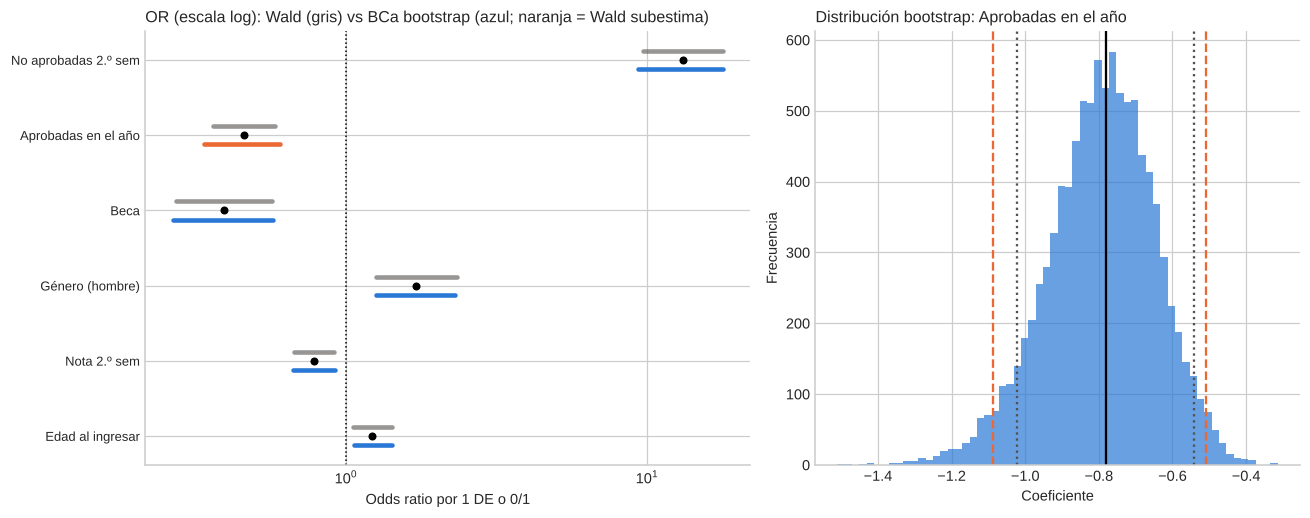

In [24]:
orden = [v for v in nombres if v != 'const']
fig, axs = plt.subplots(1, 2, figsize=(12, 0.5 * len(orden) + 1.8), gridspec_kw={'width_ratios': [1.25, 1]})
yy = np.arange(len(orden))[::-1]
for k, v in enumerate(orden):
    axs[0].plot([ic_or.loc[v, 'Wald 2.5 %'], ic_or.loc[v, 'Wald 97.5 %']], [yy[k] + 0.12] * 2, color=GRIS, lw=3, alpha=0.6)
    axs[0].plot([ic_or.loc[v, 'BCa 2.5 %'], ic_or.loc[v, 'BCa 97.5 %']], [yy[k] - 0.12] * 2,
                color=NARANJA if ic_coef.loc[v, 'Inestable'] else AZUL, lw=3)
    axs[0].scatter(ic_or.loc[v, 'OR'], yy[k], color='black', zorder=3, s=18)
axs[0].axvline(1, color='black', lw=1, ls=':')
axs[0].set_xscale('log'); axs[0].set_yticks(yy, [et(v) for v in orden], fontsize=8.5)
axs[0].set(title='OR (escala log): Wald (gris) vs BCa bootstrap (azul; naranja = Wald subestima)', xlabel='Odds ratio por 1 DE o 0/1')
var_h = orden[int(np.argmax(ic_coef.loc[orden, 'Razón de anchos (boot/Wald)'].to_numpy()))]
j = nombres.index(var_h)
axs[1].hist(coeficientes_boot[:, j], bins=60, color=AZUL, alpha=0.7)
for x in ic_bca[j]: axs[1].axvline(x, color=NARANJA, ls='--')
for x in ic_wald[j]: axs[1].axvline(x, color=GRIS, ls=':')
axs[1].axvline(beta_hat[j], color='black')
axs[1].set(title=f'Distribución bootstrap: {et(var_h)}', xlabel='Coeficiente', ylabel='Frecuencia')
plt.tight_layout(); plt.savefig(f'{FIG}/s3_fig3_bootstrap_or.png'); plt.show()

**Resultados del *bootstrap*:**

- **Ningún predictor es inestable en signo:** todos conservan su signo en ≥ 99,6 % de las remuestras y ningún IC BCa
  de los OR incluye el 1. El intercepto cambia de signo en 7 % de ellas, pero no tiene interpretación sustantiva.
- **Aprobadas en el año:** el error estándar *bootstrap* (0,147) es un 20 % mayor que el de Wald (0,123) y su IC es un
  22 % más ancho y asimétrico (OR BCa [0,34; 0,60] frente a Wald [0,36; 0,58]). El modelo clásico **subestima** su
  incertidumbre, coherente con la no linealidad detectada en 2.4. El efecto es firme, pero su magnitud debe
  comunicarse con el IC *bootstrap*.
- **No aprobadas, beca, género, nota y edad:** IC *bootstrap* y de Wald prácticamente iguales (razón de anchos
  0,98–1,08): la aproximación normal funciona bien para ellos.
- **Comparación con S2:** la beca, cuya asociación de S1 (RR bruto 3,66) confirmó la permutación de S2 (p = 0,0001),
  conserva un efecto protector robusto (OR 0,39, BCa [0,27; 0,57]) incluso después de controlar por rendimiento.

## 2.4 Diagnóstico de Supuestos

In [25]:
print("VIF del modelo final:")
vif(vars_final).round(3)

VIF del modelo final:


No aprobadas 2.º sem   2.4710
Aprobadas en el año    2.2560
Scholarship holder     1.1330
Gender                 1.1030
Nota 2.º sem           1.0590
Age at enrollment      1.1310
dtype: float64

**Multicolinealidad:** VIF entre 1,06 y 2,47, todos bajo 5. La colinealidad entre semestres quedó resuelta.

In [26]:
# Linealidad en el logit: prueba de Box-Tidwell (agrega x·ln(x) en escala original, desplazada a positivos)
num_final = [v for v in vars_final if v in NUMERICAS]
bt = []
for v in num_final:
    x = d_train[v] - d_train[v].min() + 1
    Xbt = X_train[vars_final].copy(); Xbt[f'{v}·ln'] = (x * np.log(x) - (x * np.log(x)).mean()) / (x * np.log(x)).std()
    mbt = sm.Logit(y_train, sm.add_constant(Xbt)).fit(disp=0)
    bt.append({'Variable': v, 'Coef. término x·ln(x)': mbt.params[f'{v}·ln'], 'p-valor': mbt.pvalues[f'{v}·ln']})
box_tidwell = pd.DataFrame(bt).set_index('Variable')
display(box_tidwell)

# Sensibilidad: términos cuadráticos para las numéricas con p < 0,05 en Box-Tidwell
no_lin = box_tidwell.index[box_tidwell['p-valor'] < 0.05].tolist()
Xq_tr, Xq_te = X_train[vars_final].copy(), X_test[vars_final].copy()
for v in no_lin:
    Xq_tr[v + '²'] = X_train[v] ** 2; Xq_te[v + '²'] = X_test[v] ** 2
m_q = sm.Logit(y_train, sm.add_constant(Xq_tr)).fit(disp=0)
print(f"Con términos cuadráticos {no_lin}: AIC {m_final.aic:.1f} → {m_q.aic:.1f} | AUC prueba "
      f"{roc_auc_score(y_test, m_final.predict(sm.add_constant(X_test[vars_final]))):.4f} → "
      f"{roc_auc_score(y_test, m_q.predict(sm.add_constant(Xq_te))):.4f}")

# Recomendación de S2: transformar la edad por su asimetría. Variante con log(edad) estandarizado
log_tr, log_te = np.log(d_train['Age at enrollment']), np.log(d_test['Age at enrollment'])
Xl_tr, Xl_te = X_train[vars_final].copy(), X_test[vars_final].copy()
Xl_tr['Age at enrollment'] = (log_tr - log_tr.mean()) / log_tr.std(ddof=0)
Xl_te['Age at enrollment'] = (log_te - log_tr.mean()) / log_tr.std(ddof=0)
m_log = sm.Logit(y_train, sm.add_constant(Xl_tr)).fit(disp=0)
print(f"Con log(edad): AIC {m_final.aic:.1f} → {m_log.aic:.1f} | AUC prueba "
      f"{roc_auc_score(y_test, m_final.predict(sm.add_constant(X_test[vars_final]))):.4f} → "
      f"{roc_auc_score(y_test, m_log.predict(sm.add_constant(Xl_te))):.4f}")

,Coef. término x·ln(x),p-valor
Variable,,
No aprobadas 2.º sem,1.7135,0.1690
Aprobadas en el año,6.8693,0.0000
Nota 2.º sem,1.9048,0.0077
Age at enrollment,-2.4925,0.0022


Con términos cuadráticos ['Aprobadas en el año', 'Nota 2.º sem', 'Age at enrollment']: AIC 1263.1 → 1231.3 | AUC prueba 0.9472 → 0.9508
Con log(edad): AIC 1263.1 → 1260.8 | AUC prueba 0.9472 → 0.9475


**Linealidad en el logit (Box-Tidwell):** se cumple para las no aprobadas (p = 0,17), pero se rechaza para las
aprobadas en el año, la nota del 2.º semestre y la edad (p ≤ 0,008). Con n = 2.434 la prueba detecta desviaciones
pequeñas; para medir su importancia práctica se agregaron términos cuadráticos: el AIC mejora (1.263,1 → 1.231,3) y el
AUC de prueba sube poco (0,947 → 0,951). S2 había recomendado transformar la edad por su asimetría: con log(edad) el
AIC baja solo 2,3 puntos y el AUC queda prácticamente igual (0,947 → 0,948). Se mantiene el modelo lineal con la edad acotada, porque conserva la
lectura "por año" y el cambio de ajuste es marginal; queda registrado como limitación (alternativa: *splines* o tramos).

In [27]:
glm_final = sm.GLM(y_train, sm.add_constant(X_train[vars_final]), family=sm.families.Binomial()).fit()
infl = glm_final.get_influence()
cook = pd.Series(infl.cooks_distance[0], index=X_train.index)
umbral_cook = 4 / len(cook)
influyentes = cook[cook > umbral_cook].index
print(f"Observaciones con D de Cook > 4/n = {umbral_cook:.4f}: {len(influyentes)} ({len(influyentes)/len(cook)*100:.1f} %) | "
      f"máximo D = {cook.max():.4f}")

# Perfil de los influyentes frente al resto
perfil = pd.DataFrame({'Influyentes': d_train.loc[influyentes, vars_final + [OBJETIVO]].mean(),
                       'Resto': d_train.drop(influyentes)[vars_final + [OBJETIVO]].mean()})
display(perfil.round(3))

print(f"Mayores de 40 años (outliers de S1) entre los influyentes: {(d_train.loc[influyentes, 'Age at enrollment'] >= 40).sum()}")

# Sensibilidad: reajuste sin el 1 % más influyente y sin los estudiantes de 40 años o más
top1 = cook.sort_values(ascending=False).index[:int(0.01 * len(cook))]
mayores = d_train.index[d_train['Age at enrollment'] >= 40]
auc_de = lambda m: roc_auc_score(y_test, m.predict(sm.add_constant(X_test[vars_final])))
m_top = ajustar(vars_final, X_train.drop(top1), y_train.drop(top1))
m_may = ajustar(vars_final, X_train.drop(mayores), y_train.drop(mayores))
sens_cook = pd.DataFrame({'Todos': m_final.params, f'Sin 1 % más influyente (n={len(top1)})': m_top.params,
                          f'Sin edad ≥ 40 (n={len(mayores)})': m_may.params}).T
sens_cook['AUC prueba'] = [auc_de(m) for m in (m_final, m_top, m_may)]
sens_cook

Observaciones con D de Cook > 4/n = 0.0016: 174 (7.1 %) | máximo D = 0.0208


,Influyentes,Resto
No aprobadas 2.º sem,1.2240,1.9040
Aprobadas en el año,12.4830,9.5220
Scholarship holder,0.2930,0.2670
Gender,0.3160,0.3220
Nota 2.º sem,12.6410,12.8920
Age at enrollment,24.9060,23.5940
Deserta,0.7820,0.3560


Mayores de 40 años (outliers de S1) entre los influyentes: 16


,const,No aprobadas 2.º sem,Aprobadas en el año,Scholarship holder,Gender,Nota 2.º sem,Age at enrollment,AUC prueba
Todos,-0.1622,2.5745,-0.7816,-0.9356,0.5365,-0.2461,0.2011,0.9472
Sin 1 % más influyente (n=24),-0.0816,2.8012,-1.0710,-0.8396,0.5247,-0.2783,0.2292,0.9465
Sin edad ≥ 40 (n=157),-0.0581,2.5733,-0.7529,-0.9447,0.4540,-0.2555,0.4262,0.9478


Grupos con residuo medio fuera de ±2 EE: 1 de 20
Residuos de devianza con |r| > 2: 78 (3.2 %)


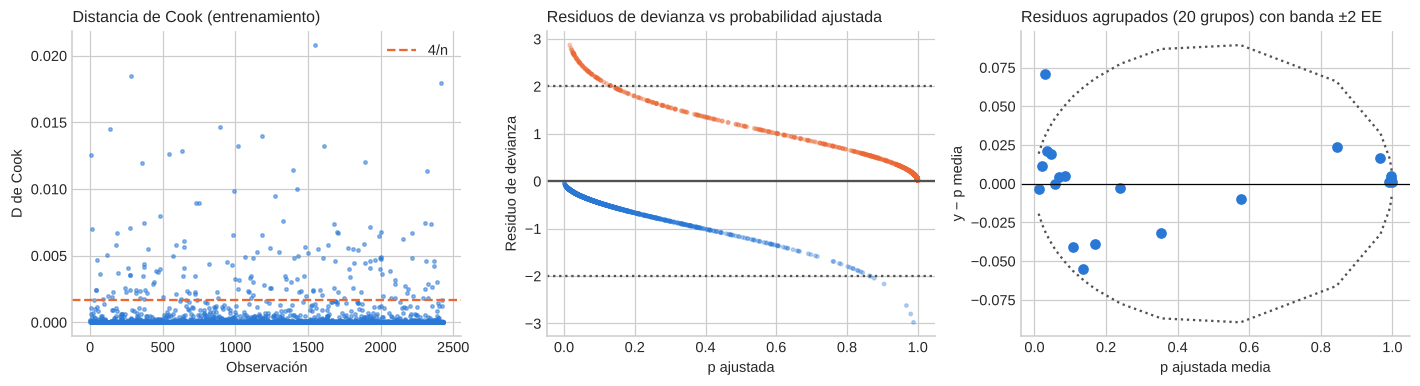

In [28]:
res_dev = glm_final.resid_deviance
p_hat = glm_final.fittedvalues
# Residuos agrupados (binned): media de y − p en 20 grupos de probabilidad predicha
grupos = pd.qcut(p_hat, 20, duplicates='drop')
binned = pd.DataFrame({'p': p_hat, 'r': y_train - p_hat}).groupby(grupos, observed=True).agg(p=('p', 'mean'), r=('r', 'mean'), n=('r', 'size'))
lim = 2 * np.sqrt(binned['p'] * (1 - binned['p']) / binned['n'])
print(f"Grupos con residuo medio fuera de ±2 EE: {(binned['r'].abs() > lim).sum()} de {len(binned)}")
print(f"Residuos de devianza con |r| > 2: {(np.abs(res_dev) > 2).sum()} ({(np.abs(res_dev) > 2).mean()*100:.1f} %)")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].scatter(range(len(cook)), cook, s=5, color=AZUL, alpha=0.5)
axs[0].axhline(umbral_cook, color=NARANJA, ls='--', label='4/n')
axs[0].set(title="Distancia de Cook (entrenamiento)", xlabel='Observación', ylabel='D de Cook'); axs[0].legend()
axs[1].scatter(p_hat, res_dev, s=5, alpha=0.3, c=np.where(y_train == 1, NARANJA, AZUL))
axs[1].axhline(0, color=GRIS); axs[1].axhline(2, color=GRIS, ls=':'); axs[1].axhline(-2, color=GRIS, ls=':')
axs[1].set(title='Residuos de devianza vs probabilidad ajustada', xlabel='p ajustada', ylabel='Residuo de devianza')
axs[2].plot(binned['p'], lim, color=GRIS, ls=':'); axs[2].plot(binned['p'], -lim, color=GRIS, ls=':')
axs[2].scatter(binned['p'], binned['r'], color=AZUL); axs[2].axhline(0, color='black', lw=0.8)
axs[2].set(title='Residuos agrupados (20 grupos) con banda ±2 EE', xlabel='p ajustada media', ylabel='y − p media')
plt.tight_layout(); plt.savefig(f'{FIG}/s3_fig4_diagnostico.png'); plt.show()

**Observaciones influyentes (D de Cook):** 174 observaciones (7,1 %) superan la regla 4/n, pero el máximo es
D = 0,021, muy lejos de 1, así que **ninguna observación individual domina el ajuste**. El perfil de los influyentes es
revelador: el 78 % son desertores con **más** aprobadas que el promedio (12,5 frente a 9,5), es decir, estudiantes que
abandonan por razones no académicas que el modelo no observa. Eliminarlos inflaría artificialmente los coeficientes
(sin el 1 % más influyente, el de aprobadas pasa de −0,78 a −1,07), por lo que **se conservan**.

**Outliers de S1:** 16 de los influyentes tienen 40 años o más. Al excluir a los 157 mayores de 40 de entrenamiento,
el coeficiente de la edad se duplica (0,20 → 0,43) y el resto casi no cambia: los mayores **atenúan** el efecto lineal
de la edad (el riesgo crece con la edad, pero no sigue creciendo igual después de los 40), lo que coincide con la no
linealidad detectada. El AUC casi no varía (0,947 → 0,948), así que la winsorización es suficiente.

**Residuos:** solo 3,2 % de los residuos de devianza superan |2| y 1 de 20 grupos de probabilidad queda fuera de la
banda ±2 EE, sin un patrón sistemático: la calibración es aceptable.

## 2.5 Evaluación de Desempeño

In [29]:
def metricas(y, p, umbral=0.5):
    yp = (p >= umbral).astype(int)
    return {'Accuracy': accuracy_score(y, yp), 'Precision': precision_score(y, yp),
            'Recall': recall_score(y, yp), 'F1': f1_score(y, yp), 'AUC': roc_auc_score(y, p)}

filas, PROBS = [], {}
for nombre, (vars_, m) in MODELOS.items():
    p_tr = m.predict(sm.add_constant(X_train[vars_]))
    p_te = m.predict(sm.add_constant(X_test[vars_]))
    PROBS[nombre] = (p_tr, p_te)
    for conj, y, p in [('Entrenamiento', y_train, p_tr), ('Prueba', y_test, p_te)]:
        filas.append({'Modelo': nombre, 'Conjunto': conj, **metricas(y, p)})
desempeno = pd.DataFrame(filas).set_index(['Modelo', 'Conjunto'])
desempeno

Accuracy  Precision  Recall     F1    AUC
Modelo            Conjunto                                                
M1 (S1/S2)        Entrenamiento    0.8874     0.8975  0.8002 0.8461 0.9206
                  Prueba           0.8937     0.9033  0.8114 0.8549 0.9251
M2 (Stepwise AIC) Entrenamiento    0.9080     0.9314  0.8225 0.8736 0.9417
                  Prueba           0.9004     0.8987  0.8362 0.8663 0.9466
M3 (Reducido)     Entrenamiento    0.9071     0.9333  0.8183 0.8720 0.9409
                  Prueba           0.9013     0.8968  0.8412 0.8681 0.9472

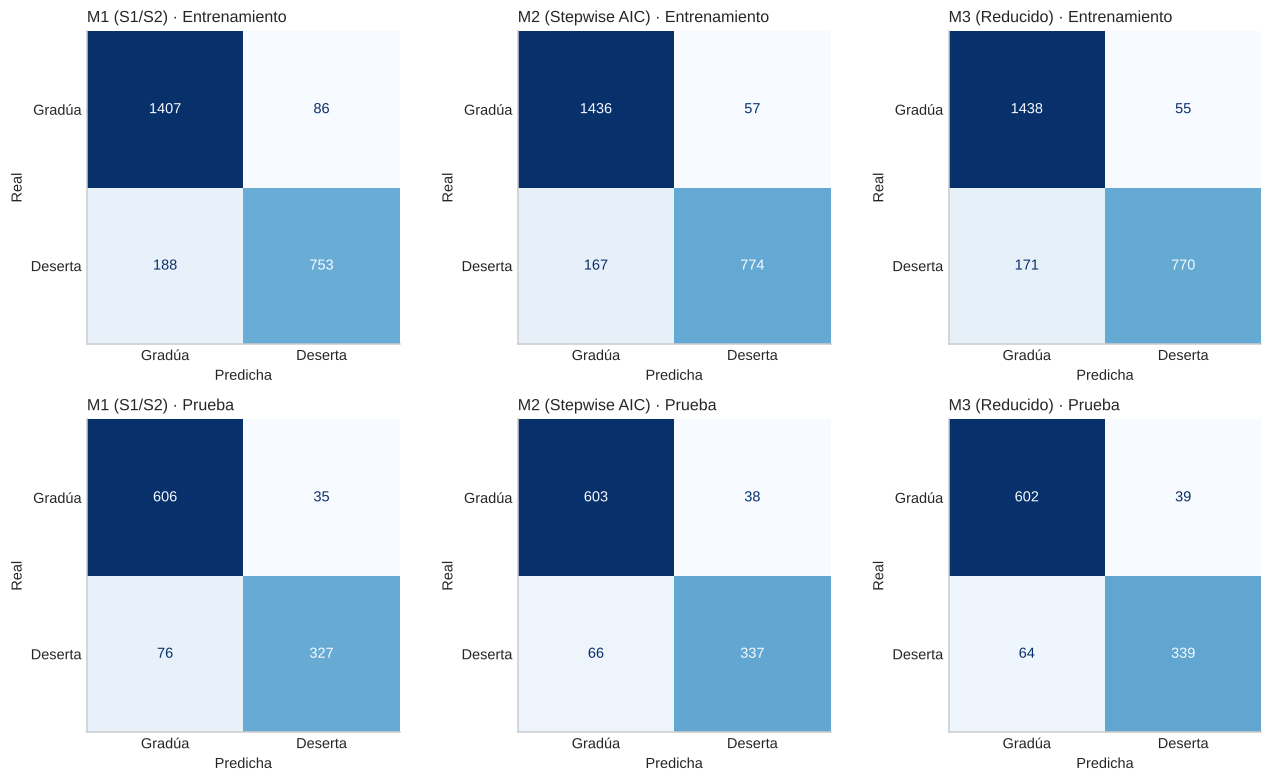

In [30]:
fig, axs = plt.subplots(2, 3, figsize=(12, 7.2))
for j, (nombre, (p_tr, p_te)) in enumerate(PROBS.items()):
    for i, (conj, y, p) in enumerate([('Entrenamiento', y_train, p_tr), ('Prueba', y_test, p_te)]):
        cm = confusion_matrix(y, (p >= 0.5).astype(int))
        ConfusionMatrixDisplay(cm, display_labels=['Gradúa', 'Deserta']).plot(
            ax=axs[i, j], cmap='Blues', colorbar=False, values_format='d')
        axs[i, j].grid(False); axs[i, j].set_title(f'{nombre} · {conj}')
        axs[i, j].set_xlabel('Predicha'); axs[i, j].set_ylabel('Real')
plt.tight_layout(); plt.savefig(f'{FIG}/s3_fig5_matrices_confusion.png'); plt.show()

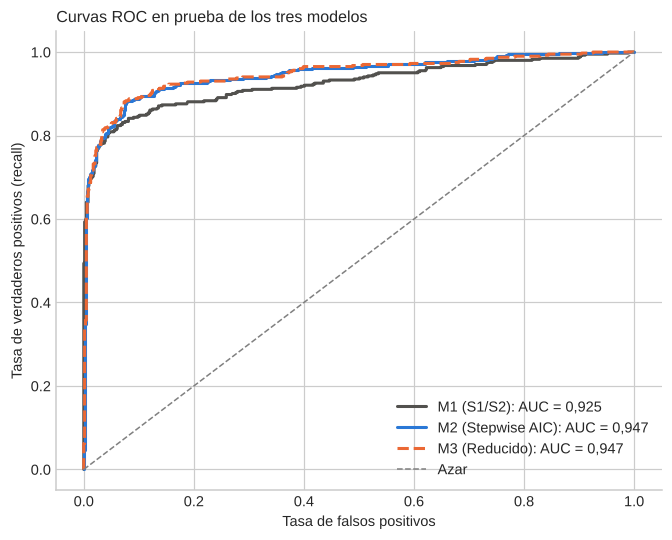

In [31]:
fig, ax = plt.subplots(figsize=(6.2, 5))
for (nombre, (_, p_te)), col, ls in zip(PROBS.items(), [GRIS, AZUL, NARANJA], ['-', '-', '--']):
    fpr, tpr, _ = roc_curve(y_test, p_te)
    ax.plot(fpr, tpr, lw=2, color=col, ls=ls, label=f'{nombre}: AUC = {auc(fpr, tpr):.3f}'.replace('.', ','))
ax.plot([0, 1], [0, 1], ls='--', color='gray', lw=1, label='Azar')
ax.set(xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos (recall)',
       title='Curvas ROC en prueba de los tres modelos')
ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(f'{FIG}/s3_fig2_roc_modelos.png'); plt.show()

### Comparación de Modelos

In [32]:
comparacion = pd.DataFrame({
    'Modelo': list(MODELOS),
    'Variables': [len(v) for v, _ in MODELOS.values()],
    'AIC': [m.aic for _, m in MODELOS.values()],
    'BIC': [m.bic for _, m in MODELOS.values()],
    'VIF máximo': [vif(v).max() for v, _ in MODELOS.values()],
    'Accuracy Test': [desempeno.loc[(k, 'Prueba'), 'Accuracy'] for k in MODELOS],
    'Recall Test': [desempeno.loc[(k, 'Prueba'), 'Recall'] for k in MODELOS],
    'F1 Test': [desempeno.loc[(k, 'Prueba'), 'F1'] for k in MODELOS],
    'AUC Test': [desempeno.loc[(k, 'Prueba'), 'AUC'] for k in MODELOS],
}).set_index('Modelo')
comparacion

,Variables,AIC,BIC,VIF máximo,Accuracy Test,Recall Test,F1 Test,AUC Test
Modelo,,,,,,,,
M1 (S1/S2),4,1574.8508,1603.8372,1.1225,0.8937,0.8114,0.8549,0.9251
M2 (Stepwise AIC),9,1261.2574,1319.2303,2.4853,0.9004,0.8362,0.8663,0.9466
M3 (Reducido),6,1263.1106,1303.6917,2.4707,0.9013,0.8412,0.8681,0.9472


**Modelo seleccionado:** **M3 (Reducido)**: aprobadas en el año, no aprobadas del 2.º semestre, beca, género, nota
del 2.º semestre y edad.

**Justificación:**

1. **Desempeño:** el mejor AUC de prueba (0,947, excelente), el mejor recall (0,841) y el mejor F1 (0,868), con M2
   prácticamente igual. Frente a M1 gana 0,022 de AUC y 3 puntos de recall: 12 desertores más detectados en prueba.
2. **Parsimonia:** M2 agrega tres variables no significativas sin mejorar ninguna métrica de prueba; el BIC de M3 es
   15,5 puntos menor que el de M2.
3. **Diagnóstico:** VIF ≤ 2,47, todos los predictores significativos y estables en el *bootstrap*.
4. **Sin sobreajuste:** el desempeño de prueba es igual o mejor que el de entrenamiento en los tres modelos.
5. **Contexto:** incluye la edad (variable imputada y outlier de S1), que el BIC descarta por solo 1 punto; la
   mantenemos porque su efecto es estable en S2 y en el *bootstrap*, y porque es útil para focalizar apoyo.

M1 (el modelo de la Formativa 2) queda como referencia: es más simple de comunicar y su AUC de 0,925 ya es excelente.

In [33]:
# Umbral de decisión: Youden calculado en ENTRENAMIENTO y aplicado a prueba
p_tr, p_te = PROBS['M3 (Reducido)']
fpr, tpr, thr = roc_curve(y_train, p_tr)
umbral_y = thr[np.argmax(tpr - fpr)]
cmp_umbral = pd.DataFrame({f'Umbral 0,50': metricas(y_test, p_te, 0.5),
                           f'Umbral Youden {umbral_y:.2f}': metricas(y_test, p_te, umbral_y)}).T
print(f"Umbral de Youden (entrenamiento): {umbral_y:.3f}")
print("Matriz de confusión en prueba con umbral de Youden:")
print(confusion_matrix(y_test, (p_te >= umbral_y).astype(int)))
cmp_umbral

Umbral de Youden (entrenamiento): 0.380
Matriz de confusión en prueba con umbral de Youden:
[[594  47]
 [ 51 352]]


,Accuracy,Precision,Recall,F1,AUC
"Umbral 0,50",0.9013,0.8968,0.8412,0.8681,0.9472
Umbral Youden 0.38,0.9061,0.8822,0.8734,0.8778,0.9472


**Umbral de decisión.** Con el umbral de Youden calculado en entrenamiento (0,38), el recall sube de 0,841 a 0,873
(13 desertores más detectados) a cambio de 8 falsos positivos adicionales, y la accuracy incluso sube (0,901 → 0,906).

### Ponderación de clases (retroalimentación de la Formativa 2)

Como el 38,64 % deserta, se reajustan M1 y el modelo final dando más peso a los desertores (peso n / (2 · n_clase):
1,29 para desertores y 0,82 para graduados) y se cuentan los desertores sin alerta en prueba.

In [34]:
# Ponderación de clases (retroalimentación de la Formativa 2): peso n / (2 · n_clase) en entrenamiento
peso_d = len(y_train) / (2 * y_train.sum()); peso_g = len(y_train) / (2 * (len(y_train) - y_train.sum()))
print(f"Pesos: desertores = {peso_d:.3f} | graduados = {peso_g:.3f}")
filas = []
for nombre, vars_ in [('M1 (S1/S2)', vars_m1), ('M3 (Reducido)', vars_final)]:
    for etiqueta, w in [('Sin ponderar', None), ('Ponderado', 'balanced')]:
        lg = LogisticRegression(penalty=None, class_weight=w, max_iter=5000).fit(X_train[vars_], y_train)
        p = lg.predict_proba(X_test[vars_])[:, 1]
        vn, fp, fn, vp = confusion_matrix(y_test, (p >= 0.5).astype(int)).ravel()
        filas.append({'Modelo': nombre, 'Versión': etiqueta, 'VP': vp, 'FN (sin alerta)': fn, 'FP': fp,
                      'Recall': vp / (vp + fn), 'Precision': vp / (vp + fp), 'AUC': roc_auc_score(y_test, p)})
ponderacion = pd.DataFrame(filas).set_index(['Modelo', 'Versión'])
print("Referencia Formativa 2: 75 desertores sin alerta, recall 0,814, AUC 0,925")
ponderacion

Pesos: desertores = 1.293 | graduados = 0.815
Referencia Formativa 2: 75 desertores sin alerta, recall 0,814, AUC 0,925


VP  FN (sin alerta)  FP  Recall  Precision    AUC
Modelo        Versión                                                         
M1 (S1/S2)    Sin ponderar  327               76  35  0.8114     0.9033 0.9251
              Ponderado     339               64  64  0.8412     0.8412 0.9259
M3 (Reducido) Sin ponderar  339               64  39  0.8412     0.8968 0.9472
              Ponderado     352               51  46  0.8734     0.8844 0.9470

**Resultado:** con M1, el modelo de la Formativa 2, la ponderación recupera **12 de los 76 desertores sin alerta**
(quedan 64; en la Formativa 2 eran 75) y el recall sube de 0,811 a 0,841, a cambio de bajar la precisión de 0,903 a
0,841. Con el modelo final, recupera **13 de 64** (quedan 51) y el recall llega a 0,873 con precisión 0,884. El AUC no
cambia (0,926 y 0,947), porque ponderar casi solo desplaza el intercepto: ordena a los estudiantes igual y equivale
a bajar el umbral, como confirma que el resultado del modelo final coincide con el umbral de Youden (352 desertores
detectados en ambos casos). Como en un sistema de alerta temprana es más costoso no detectar a un desertor que ofrecer
una tutoría de más, recomendamos operar el modelo final con el umbral 0,38 (o, de forma equivalente, ponderado).

In [35]:
# Sensibilidad del modelo final a la matrícula al día y deudor (excluidas por riesgo de fuga)
def X_con(d, extra):
    X = preparar_X(d); X[extra] = d[extra].astype(float); return X
extra = ['Tuition fees up to date', 'Debtor']
Xtr_e, Xte_e = X_con(d_train, extra), X_con(d_test, extra)
m_e = sm.Logit(y_train, sm.add_constant(Xtr_e[vars_final + extra])).fit(disp=0)
print(f"AUC prueba modelo final: {roc_auc_score(y_test, PROBS['M3 (Reducido)'][1]):.4f} | "
      f"con matrícula y deudor: {roc_auc_score(y_test, m_e.predict(sm.add_constant(Xte_e[vars_final + extra]))):.4f}")
tabla_or(m_e).loc[extra]

AUC prueba modelo final: 0.9472 | con matrícula y deudor: 0.9526


,Coef.,OR,OR IC 2.5 %,OR IC 97.5 %,p-valor
Tuition fees up to date,-2.6533,0.0704,0.0373,0.1328,0.0000
Debtor,1.1937,3.2991,1.9036,5.7177,0.0000


**Sensibilidad a la fuga de información:** agregar la matrícula al día y la condición de deudor sube el AUC solo de
0,947 a 0,953. La ganancia es pequeña frente al riesgo de usar información posterior al abandono, lo que confirma la
decisión de excluirlas. Si la universidad puede registrar el atraso **en tiempo real** (por ejemplo, la primera cuota
impaga), esa señal sí sería legítima y valiosa.

---
# PARTE 3: Análisis Comparativo de Imputación

El modelo final (mismas seis variables) se reajusta en cada dataset, repitiendo dentro de cada uno la misma
preparación (acotar la edad y estandarizar con su propio entrenamiento). Se agrega como referencia el ajuste con
los valores verdaderos.

In [36]:
res_imp, coefs_imp = [], {}
for nombre, (trn, tst) in {**DATASETS, 'Referencia: valores verdaderos': (df_verdad.loc[idx_train], df_verdad.loc[idx_test])}.items():
    trn, tst = trn.copy(), tst.copy()
    # misma preparación que en 2.1, re-estimada dentro de cada dataset (acotar edad y estandarizar)
    p99 = trn['Age at enrollment'].quantile(0.99)
    for d in (trn, tst): d['Age at enrollment'] = d['Age at enrollment'].clip(upper=p99)
    agregar_variables_f2(trn, tst)
    sc = StandardScaler().fit(trn[NUMERICAS])
    Xtr_, Xte_ = trn[CANDIDATAS].astype(float), tst[CANDIDATAS].astype(float)
    Xtr_[NUMERICAS] = sc.transform(trn[NUMERICAS]); Xte_[NUMERICAS] = sc.transform(tst[NUMERICAS])
    m = sm.Logit(trn[OBJETIVO], sm.add_constant(Xtr_[vars_final])).fit(disp=0)
    p = m.predict(sm.add_constant(Xte_[vars_final]))
    ic = m.conf_int()
    coefs_imp[nombre] = pd.DataFrame({'Coef.': m.params, 'IC 2.5 %': ic[0], 'IC 97.5 %': ic[1], 'p': m.pvalues})
    res_imp.append({'Estrategia': nombre, 'n entrenamiento': len(trn), 'n prueba': len(tst),
                    'AUC Test': roc_auc_score(tst[OBJETIVO], p),
                    'Accuracy Test': accuracy_score(tst[OBJETIVO], (p >= 0.5).astype(int)),
                    'Recall Test': recall_score(tst[OBJETIVO], (p >= 0.5).astype(int)),
                    'Ancho IC promedio': (ic[1] - ic[0]).drop('const').mean()})
comparacion_imputacion = pd.DataFrame(res_imp).set_index('Estrategia')
comparacion_imputacion

,n entrenamiento,n prueba,AUC Test,Accuracy Test,Recall Test,Ancho IC promedio
Estrategia,,,,,,
A: Eliminar,1876,805,0.9454,0.9019,0.8355,0.5813
B: Imp. simple,2434,1044,0.9471,0.9033,0.8437,0.5075
C: Imp. regresión,2434,1044,0.9472,0.9013,0.8412,0.5071
Referencia: valores verdaderos,2434,1044,0.9474,0.9023,0.8437,0.5068


,A: Eliminar · coef.,B: Imp. simple · coef.,C: Imp. regresión · coef.,Referencia: valores verdaderos · coef.
const,-0.1310,-0.1670,-0.1620,-0.1640
No aprobadas 2.º sem,2.4430,2.5700,2.5740,2.5720
Aprobadas en el año,-0.8870,-0.7850,-0.7820,-0.7850
Scholarship holder,-1.0590,-0.9390,-0.9360,-0.9360
Gender,0.4570,0.5490,0.5360,0.5420
Nota 2.º sem,-0.2040,-0.2480,-0.2460,-0.2460
Age at enrollment,0.1780,0.1800,0.2010,0.1990


,A: Eliminar · ancho IC,B: Imp. simple · ancho IC,C: Imp. regresión · ancho IC,Referencia: valores verdaderos · ancho IC
const,0.5130,0.4510,0.4520,0.4520
No aprobadas 2.º sem,0.6860,0.6150,0.6150,0.6150
Aprobadas en el año,0.5880,0.4820,0.4810,0.4810
Scholarship holder,0.8350,0.7290,0.7300,0.7300
Gender,0.7010,0.6150,0.6170,0.6160
Nota 2.º sem,0.3350,0.3000,0.3000,0.3000
Age at enrollment,0.3420,0.3040,0.3000,0.3000


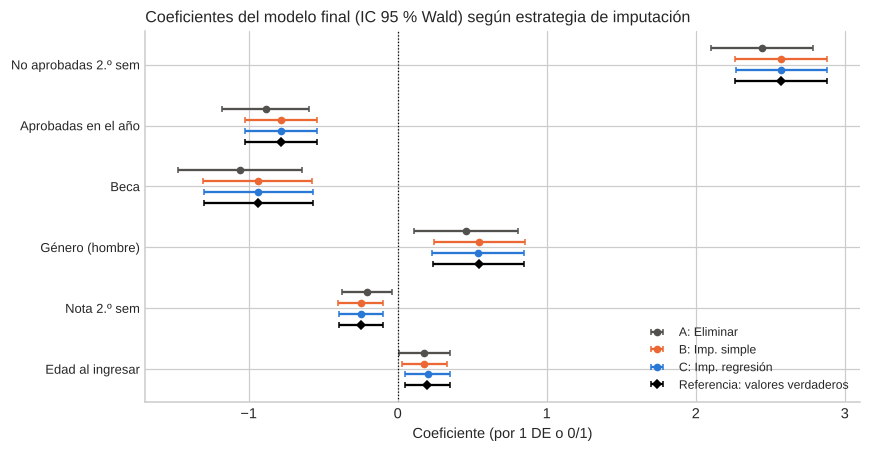

In [37]:
tabla_coefs_imp = pd.concat({k: v['Coef.'] for k, v in coefs_imp.items()}, axis=1)
tabla_anchos_imp = pd.concat({k: v['IC 97.5 %'] - v['IC 2.5 %'] for k, v in coefs_imp.items()}, axis=1)
display(tabla_coefs_imp.round(3).add_suffix(' · coef.'))
display(tabla_anchos_imp.round(3).add_suffix(' · ancho IC'))

fig, ax = plt.subplots(figsize=(8, 0.45 * len(vars_final) + 1.5))
yy = np.arange(len(vars_final))[::-1]
for (nombre, t), col, dy in zip(coefs_imp.items(), [GRIS, NARANJA, AZUL, 'black'], [0.27, 0.09, -0.09, -0.27]):
    t = t.loc[vars_final]
    ax.errorbar(t['Coef.'], yy + dy, xerr=[t['Coef.'] - t['IC 2.5 %'], t['IC 97.5 %'] - t['Coef.']],
                fmt='D' if nombre.startswith('Ref') else 'o', color=col, capsize=2, ms=4, label=nombre)
ax.axvline(0, color='black', lw=0.8, ls=':')
ax.set_yticks(yy, [et(v) for v in vars_final], fontsize=8.5)
ax.set(title='Coeficientes del modelo final (IC 95 % Wald) según estrategia de imputación', xlabel='Coeficiente (por 1 DE o 0/1)')
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/s3_fig6_impacto_imputacion.png'); plt.show()

### Conclusión sobre Imputación

**¿La estrategia de imputación cambió las conclusiones?** **No en las conclusiones sustantivas**, pero sí en la
precisión y en el tamaño de un efecto:

- **Desempeño:** el AUC de prueba es prácticamente igual en las tres estrategias (0,945–0,947), porque las variables
  con más peso (aprobadas, no aprobadas, beca) no tienen faltantes.
- **Precisión (A):** eliminar filas reduce el entrenamiento de 2.434 a 1.876 casos y ensancha los IC un 15 % en
  promedio (0,58 frente a 0,51). Además, mueve varios coeficientes (beca −1,06, género 0,46, nota −0,20) más que las
  imputaciones, solo por perder 23 % de la muestra.
- **Sesgo en la variable imputada (B):** la mediana **atenúa el efecto de la edad** un 10 % (0,180 frente al verdadero
  0,199), porque asigna 20 años a estudiantes que en realidad eran mayores. La regresión lo recupera casi exacto
  (0,201) y es la estrategia más parecida a la referencia en todos los coeficientes.

**¿Qué estrategia recomiendas?** **C (regresión)**: conserva el tamaño de muestra, no sesga el coeficiente de la
variable imputada y su error de imputación es el menor. B sería aceptable si solo importara la predicción.

**Limitaciones:** (1) la regresión imputa un valor sin ruido, por lo que encoge un poco la varianza; una imputación
múltiple (por ejemplo, MICE) propagaría la incertidumbre de la imputación a los IC; (2) los faltantes son MCAR
simulados: con faltantes MAR o MNAR reales las diferencias entre estrategias serían mayores; (3) la comparación
con la "verdad" solo es posible porque guardamos los originales.

---
# PARTE 4: Conclusiones Integradas

In [38]:
# Resumen para el informe y la presentación
p_te = PROBS['M3 (Reducido)'][1]
print("Modelo final:", vars_final)
print(pd.Series(metricas(y_test, p_te)).round(4))
ic_or.drop('const')[['OR', 'BCa 2.5 %', 'BCa 97.5 %', 'OR por unidad original']].round(3)

Modelo final: ['No aprobadas 2.º sem', 'Aprobadas en el año', 'Scholarship holder', 'Gender', 'Nota 2.º sem', 'Age at enrollment']
Accuracy    0.9013
Precision   0.8968
Recall      0.8412
F1          0.8681
AUC         0.9472
dtype: float64


,OR,BCa 2.5 %,BCa 97.5 %,OR por unidad original
No aprobadas 2.º sem,13.1250,9.3500,17.8350,3.1270
Aprobadas en el año,0.4580,0.3370,0.6020,0.8800
Scholarship holder,0.3920,0.2660,0.5730,0.3920
Gender,1.7100,1.2540,2.2990,1.7100
Nota 2.º sem,0.7820,0.6640,0.9180,0.8230
Age at enrollment,1.2230,1.0600,1.4240,1.0270


## Resumen S1 → S2 → S3

**Hallazgos S1 (Exploración):** 38,6 % de deserción en n = 3.478. El rendimiento del 2.º semestre fue el factor más
discriminante (r = −0,69, d = −1,94), seguido por beca (V = 0,32) y matrícula al día (z = 26,42). Se detectaron
12 % de faltantes MCAR, edad muy asimétrica con 186 casos de 40 años o más y colinealidad entre semestres (r = 0,91).

**Hallazgos S2 (Validación):** el *bootstrap* (percentil y BCa) y la permutación confirmaron esos efectos y la
estabilidad de las correlaciones académicas y de la edad; solo la tasa de desempleo fue inestable. La simulación
Monte Carlo dimensionó en 412 los cupos de tutoría necesarios para una cohorte de 1.000 estudiantes al 95 %.

**Hallazgos S3 (Modelamiento):** la imputación por regresión, ajustada solo en entrenamiento, redujo a la mitad el
error de la edad y fue la única estrategia que no sesgó su coeficiente. Tres criterios de selección coincidieron
en el mismo núcleo de variables, que conserva las de la Formativa 2; el modelo final alcanzó AUC = 0,947 en prueba
(0,925 en la Formativa 2) y sus coeficientes son estables en 10.000 remuestras.

## Modelo Final

**Variables incluidas:** aprobadas en el año, no aprobadas del 2.º semestre, beca, género, nota del 2.º semestre y
edad al ingresar.

**Desempeño (prueba, umbral 0,5):** AUC 0,947 · accuracy 0,901 · precisión 0,897 · recall 0,841 · F1 0,868
(con umbral 0,38: recall 0,873).

**Interpretación de Odds Ratios (IC 95 % BCa):**
- Cada unidad inscrita y **no aprobada** en el 2.º semestre multiplica las odds de desertar por **3,1** (OR por DE 13,1 [9,3; 17,8]).
- Cada unidad **aprobada** en el año las reduce un **12 %** (OR por DE 0,46 [0,34; 0,60]).
- La **beca** las reduce un **61 %** (OR 0,39 [0,27; 0,57]).
- Los **hombres** tienen odds 71 % mayores (OR 1,71 [1,25; 2,30]).
- Cada **punto de nota** del 2.º semestre las reduce un **18 %** (OR por DE 0,78 [0,66; 0,92]).
- Cada **año de edad** al ingresar las aumenta un 2,7 % (OR por DE 1,22 [1,06; 1,42]).

## Recomendaciones para Toma de Decisiones

1. **Alerta temprana al cierre del 2.º semestre** basada en unidades no aprobadas: es la señal más fuerte y se conoce
   antes de la matrícula del segundo año.
2. **Mantener y focalizar las becas:** su efecto protector se sostiene en S1, S2 y S3, incluso controlando por
   rendimiento.
3. **Usar el umbral 0,38** y dimensionar las tutorías con el resultado de S2 (≈ 412 cupos por cada 1.000 estudiantes).
4. **Registrar la morosidad en tiempo real** para poder incorporarla como predictor sin fuga de información.
5. **Indagar las causas no académicas:** el 78 % de las observaciones influyentes son desertores con buen
   rendimiento, que el modelo no puede anticipar con estos datos.

## Limitaciones del Análisis

- El modelo usa información del primer año completo; no sirve para predecir al momento del ingreso.
- No linealidad en el logit para aprobadas, nota y edad (impacto práctico pequeño en el AUC).
- La nota del 2.º semestre de los 650 estudiantes sin nota se imputó con una constante (faltante estructural, no MCAR).
- Faltantes MCAR simulados e imputación de valor único (sin propagar su incertidumbre).
- Una sola partición 70/30; el *bootstrap* mide la estabilidad de los coeficientes, no la variabilidad del AUC.
- Asociación no implica causalidad: el efecto de la beca puede reflejar características de quienes la obtienen.

---
## Checklist de Integración

- [x] ¿Referencio matriz de correlaciones de S1? (selección de predictores de imputación y de M1)
- [x] ¿Uso correlaciones estables de S2? (filtro de predictores; desempleo descartado en M1)
- [x] ¿Trato outliers de S1? (edad acotada en P99, influencia revisada con Cook)
- [x] ¿Aplico bootstrap de S2 al modelo? (10.000 remuestras, percentil y BCa)
- [x] ¿Construyo IC bootstrap para OR?
- [x] ¿Mi análisis muestra progresión S1→S2→S3?

---
*Notebook completado por Grupo 8 (Matias Manriquez Ortiz, Daniel Pérez Ramírez, Abigaíl Robles Chávez y Roberto Sánchez Saldivia) - 28/10/2026*